# Assignment 4

Alex Matteson

Github link: 

In [1]:
# imports
import exifread
from fractions import Fraction
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt
import pandas as pd

import rawpy
import imageio.v3 as iio
import os
from fractions import Fraction
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from matplotlib.colors import ListedColormap
import sys
#from scipy.optimize import brentq
from scipy.special import erf
import matplotlib
import psu_imaging as psu
import sys
from pathlib import Path
from scipy.stats import theilslopes
from pathlib import Path

import math
from scipy.signal import windows

### Part 1: From raw file to patch values

1. Inventory your captures and confirm that every one of them is a Bayer raw file from the same camera, and that the ISO and exposure time are identical within each round. Then check every frame for clipping, which is the one defect that cannot be repaired afterwards. Do not take the white level recorded in the file on trust: histogram the raw values and look for a spike at the top of the range, because a file that saturates below its own declared white level will hand you patches pinned to a ceiling that look perfectly reasonable in every other respect. Look only at the very top of the histogram. Raw files are often quantized coarsely at high signal, which scatters smaller spikes through the upper half, and a search that starts from mid scale will find one of those instead. Any clipped patch has to be excluded from everything that follows, and the outdoor round is where you are most likely to find one.
Deliverable: A list of your files with the round, chart, ISO, and exposure time of each, the lens_id assertion from the Project 1 page passing across all of them, the raw value at which your files actually saturate, and the fraction of each frame that reaches

In [2]:
# view chart captures labeled with meta data:

# Labels by position within each folder (I think the naming conventions should make this work)
POSITION_LABELS = ["chart 1", "chart 2", "chart 3", "white field"]

#helper functions:

def _ratio_to_float(value):
    """exifread values are lists of Ratio / int; return a float or None."""
    try:
        v = value.values[0] if hasattr(value, "values") else value
        return float(Fraction(v.num, v.den)) if hasattr(v, "num") else float(v)
    except Exception:
        return None
 
 
def read_exif(path):
    """Return (iso, exposure_seconds, capture_time_str) for a DNG file."""
    with open(path, "rb") as f:
        tags = exifread.process_file(f, details=False)
 
    iso = None
    for key in ("EXIF ISOSpeedRatings", "EXIF PhotographicSensitivity",
                "Image ISOSpeedRatings"):
        if key in tags:
            iso = _ratio_to_float(tags[key])
            break
 
    exposure = None
    for key in ("EXIF ExposureTime", "Image ExposureTime"):
        if key in tags:
            exposure = _ratio_to_float(tags[key])
            break
 
    when = None
    for key in ("EXIF DateTimeOriginal", "Image DateTime"):
        if key in tags:
            when = str(tags[key])
            break
 
    return (int(iso) if iso is not None else None), exposure, when
 
 
def format_exposure(seconds):
    if seconds is None:
        return "exp n/a"
    if seconds >= 1:
        return f"{seconds:g} s"
    return f"1/{round(1 / seconds)} s"
 
 
def load_dng(path, half_size=True):
    """Demosaic a DNG into an 8-bit RGB array for display."""
    with rawpy.imread(str(path)) as raw:
        return raw.postprocess(use_camera_wb=True, half_size=half_size,
                               no_auto_bright=False, output_bps=8)
 
 
def find_condition_folders(paths):
    """Each returned folder is one lighting condition.
 
    Pass either one parent folder (its sub-folders are the conditions),
    one folder that directly holds .dng files, or a list of folders.
    """
    if isinstance(paths, (str, Path)):
        paths = [paths]
    paths = [Path(p).expanduser() for p in paths]
    if len(paths) == 1:
        root = paths[0]
        if any(p.suffix.lower() == ".dng" for p in root.iterdir()):
            return [root]
        return sorted(p for p in root.iterdir() if p.is_dir())
    return paths
 
 
def list_dngs(folder, sort_by="name"):
    files = [p for p in Path(folder).iterdir()
             if p.is_file() and p.suffix.lower() == ".dng"]
    if sort_by == "time":
        files.sort(key=lambda p: (read_exif(p)[2] or "", p.name))
    else:
        files.sort(key=lambda p: p.name.lower())
    return files
 
 
def show_charts(paths, sort_by="name", full_res=False, save=None):
    """Display all DNGs in a grid (row = folder, column = position in folder).
 
    Returns a pandas DataFrame with folder, position, file, ISO and exposure.
    sort_by: "name" (file name order) or "time" (capture time order).
    save:    optional file name to save the figure, e.g. "overview.png".
    """
    folders = find_condition_folders(paths)
    if not folders:
        raise ValueError("No folders found.")
 
    n_rows, n_cols = len(folders), len(POSITION_LABELS)
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(3.6 * n_cols, 3.4 * n_rows),
                             squeeze=False)
    records = []
 
    for r, folder in enumerate(folders):
        files = list_dngs(folder, sort_by)
        if len(files) != n_cols:
            print(f"[warn] {folder.name}: found {len(files)} DNG files, "
                  f"expected {n_cols}")
 
        for c in range(n_cols):
            ax = axes[r][c]
            ax.axis("off")
            label = POSITION_LABELS[c]
            if c >= len(files):
                ax.set_title(f"Folder {r + 1} ({folder.name})\n{label}: missing",
                             fontsize=8)
                continue
 
            path = files[c]
            iso, exposure, when = read_exif(path)
            try:
                img = load_dng(path, half_size=not full_res)
            except Exception as e:
                print(f"[error] could not load {path}: {e}")
                ax.set_title(f"Folder {r + 1}, {label}\nload failed", fontsize=8)
                continue
 
            iso_txt = f"ISO {iso}" if iso is not None else "ISO n/a"
            ax.imshow(img)
            ax.set_title(f"Folder {r + 1} ({folder.name}) | {label}\n"
                         f"{iso_txt}, {format_exposure(exposure)}\n{path.name}",
                         fontsize=8)
            records.append({
                "folder_idx": r + 1,
                "folder": folder.name,
                "position": label,
                "file": path.name,
                "iso": iso,
                "exposure_s": exposure,
                "exposure": format_exposure(exposure),
                "captured": when,
            })
 
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=150)
    plt.show()
    return pd.DataFrame(records)


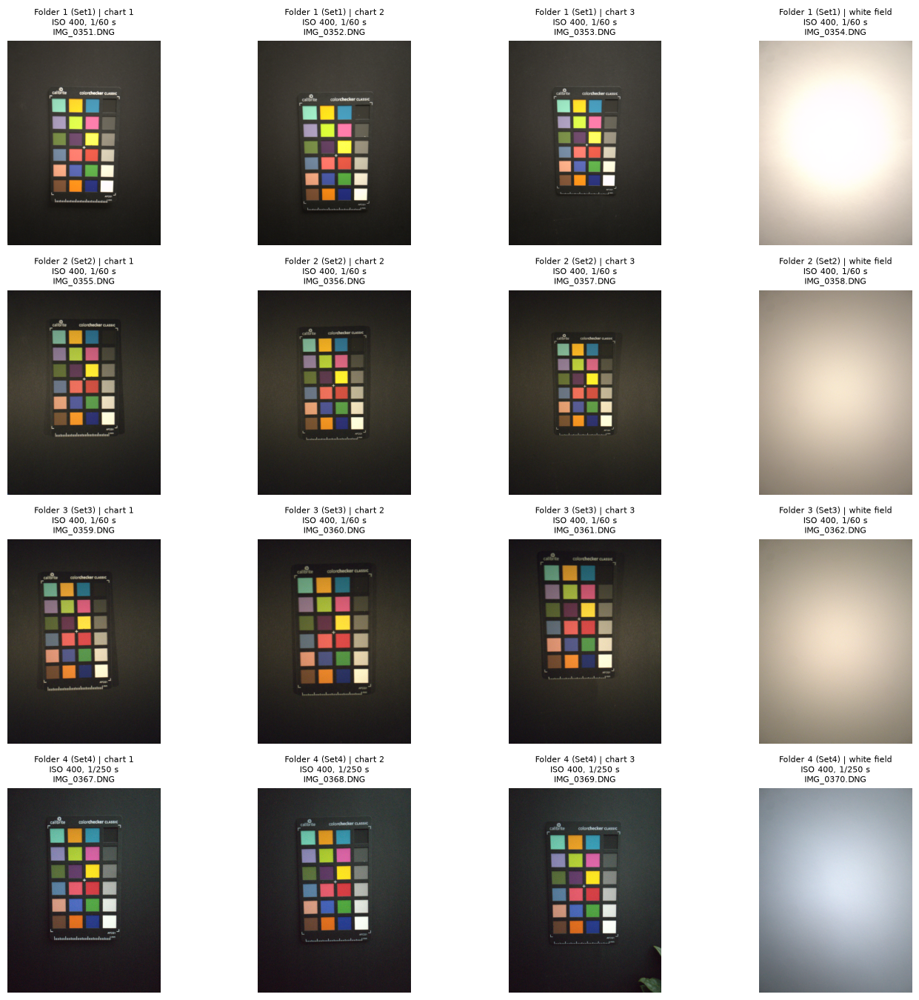

,folder_idx,folder,position,file,iso,exposure_s,exposure,captured
0,1,Set1,chart 1,IMG_0351.DNG,400,0.016667,1/60 s,2026:10:20 17:37:14
1,1,Set1,chart 2,IMG_0352.DNG,400,0.016667,1/60 s,2026:10:20 17:37:19
2,1,Set1,chart 3,IMG_0353.DNG,400,0.016667,1/60 s,2026:10:20 17:37:23
3,1,Set1,white field,IMG_0354.DNG,400,0.016667,1/60 s,2026:10:20 17:37:26
4,2,Set2,chart 1,IMG_0355.DNG,400,0.016667,1/60 s,2026:10:20 17:44:27
5,2,Set2,chart 2,IMG_0356.DNG,400,0.016667,1/60 s,2026:10:20 17:44:31
6,2,Set2,chart 3,IMG_0357.DNG,400,0.016667,1/60 s,2026:10:20 17:44:35
7,2,Set2,white field,IMG_0358.DNG,400,0.016667,1/60 s,2026:10:20 17:44:40
8,3,Set3,chart 1,IMG_0359.DNG,400,0.016667,1/60 s,2026:10:20 17:52:09
9,3,Set3,chart 2,IMG_0360.DNG,400,0.016667,1/60 s,2026:10:20 17:52:14


In [3]:
%matplotlib inline
df = show_charts(r"C:\Users\ammat\Documents\Assignment4 Captures")   # or a list of folder paths
df

In [4]:
# run the assert for one camera:
# Run in its own cell AFTER the cell that defines find_condition_folders / list_dngs.
# Needs tifffile in the environment:  uv add tifffile   (then restart the kernel)

import tifffile
import pandas as pd

CAPTURE_ROOT = r"C:\Users\ammat\Documents\Assignment4 Captures"   


def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif.get("FocalLength")
        focal = round(fl[0] / fl[1], 3) if fl else None
        return (exif.get("LensModel", "unknown"),
                focal,
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


# every DNG in every condition folder
my_capture_series = [f for folder in find_condition_folders(CAPTURE_ROOT)
                     for f in list_dngs(folder)]
print(f"Checking {len(my_capture_series)} files...")

rows, failed = [], []
for f in my_capture_series:
    try:
        model, focal, focal35, size = lens_id(f)
        rows.append({"folder": f.parent.name, "file": f.name, "lens": model,
                     "focal_mm": focal, "focal_35mm": focal35, "size": size})
    except Exception as e:
        failed.append((f, repr(e)))

lens_df = pd.DataFrame(rows)
display(lens_df)

if failed:
    print("\nCould not read lens info from:")
    for f, err in failed:
        print(f"  {f.parent.name}/{f.name}: {err}")

ids = {(r["lens"], r["focal_mm"], r["focal_35mm"], r["size"]) for r in rows}
assert not failed, "some files could not be read (see above)"
assert len(ids) == 1, f"more than one camera in this series: {ids}"
print("OK: all captures share the same lens, focal length and image size:", ids.pop())

Checking 16 files...


,folder,file,lens,focal_mm,focal_35mm,size
0,Set1,IMG_0351.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
1,Set1,IMG_0352.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
2,Set1,IMG_0353.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
3,Set1,IMG_0354.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
4,Set2,IMG_0355.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
5,Set2,IMG_0356.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
6,Set2,IMG_0357.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
7,Set2,IMG_0358.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
8,Set3,IMG_0359.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"
9,Set3,IMG_0360.DNG,iPhone 12 mini back camera 4.2mm f/1.6,4.2,26,"(4032, 3024)"


OK: all captures share the same lens, focal length and image size: ('iPhone 12 mini back camera 4.2mm f/1.6', 4.2, 26, (4032, 3024))


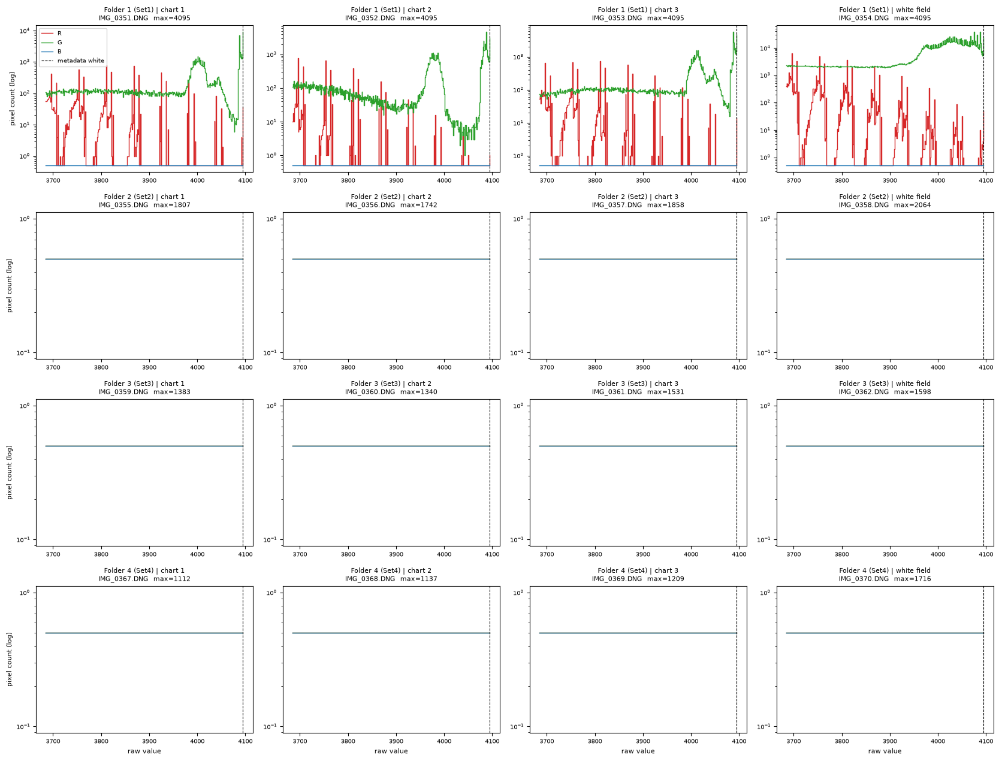

,folder_idx,folder,position,file,max_value,white_level_meta,black_level,n_at_max,frac_at_max,spike_ratio,bit_depth_guess
0,1,Set1,chart 1,IMG_0351.DNG,4095,4095,"[528, 528, 528, 528]",9066,7.435555e-04,96.446809,12
1,1,Set1,chart 2,IMG_0352.DNG,4095,4095,"[528, 528, 528, 528]",3115,2.554793e-04,389.375000,12
2,1,Set1,chart 3,IMG_0353.DNG,4095,4095,"[528, 528, 528, 528]",4803,3.939220e-04,25.146597,12
3,1,Set1,white field,IMG_0354.DNG,4095,4095,"[528, 528, 528, 528]",23934,1.962967e-03,1.675816,12
4,2,Set2,chart 1,IMG_0355.DNG,1807,4095,"[528, 528, 528, 528]",1,8.201583e-08,1.000000,11
5,2,Set2,chart 2,IMG_0356.DNG,1742,4095,"[528, 528, 528, 528]",3,2.460475e-07,3.000000,11
6,2,Set2,chart 3,IMG_0357.DNG,1858,4095,"[528, 528, 528, 528]",1,8.201583e-08,1.000000,11
7,2,Set2,white field,IMG_0358.DNG,2064,4095,"[528, 528, 528, 528]",1,8.201583e-08,1.000000,12
8,3,Set3,chart 1,IMG_0359.DNG,1383,4095,"[528, 528, 528, 528]",2,1.640317e-07,1.000000,11
9,3,Set3,chart 2,IMG_0360.DNG,1340,4095,"[528, 528, 528, 528]",1,8.201583e-08,0.500000,11


In [5]:
# get white level histograms:
# Run in its own cell AFTER the cell that defines find_condition_folders,
# list_dngs and POSITION_LABELS (from dng_charts_notebook.py).
#
# For every DNG: histogram of the RAW sensor values (no demosaic, no white
# balance, no black-level subtraction), one line per Bayer channel, zoomed to the
# TOP of the range only, log y-axis. A saturated sensor shows up as a tall spike
# at (or just below) the highest values.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rawpy

CAPTURE_ROOT = r"C:\Users\ammat\Documents\Assignment4 Captures"
TOP_FRAC = 0.1        # show only the top 5% of the range (0.95*white .. max)
CHANNEL_NAMES = {0: "R", 1: "G", 2: "B", 3: "G"}      # raw_colors: 3 is the 2nd green
CHANNEL_COLORS = {"R": "tab:red", "G": "tab:green", "B": "tab:blue"}


def raw_top_histogram(path, top_frac=TOP_FRAC):
    """Return (histograms, stats) for one DNG.

    histograms: {channel: (bin_values, counts)} covering only the top of the range
    stats:      dict with max value, pixels at max, metadata white level, ...
    """
    with rawpy.imread(str(path)) as raw:
        img = raw.raw_image_visible.copy()            # copy: view dies with the file
        colors = raw.raw_colors_visible.copy()
        white_meta = int(raw.white_level)
        black = [int(b) for b in raw.black_level_per_channel]

    vmax = int(img.max())
    ceiling = max(white_meta, vmax)
    lo = int(ceiling * (1 - top_frac))
    bins = np.arange(lo, ceiling + 2)                 # one bin per integer value

    hists = {}
    for ch_id, name in CHANNEL_NAMES.items():
        vals = img[colors == ch_id]
        h, _ = np.histogram(vals, bins=bins)
        if name in hists:                             # merge the two greens
            hists[name] = (bins[:-1], hists[name][1] + h)
        else:
            hists[name] = (bins[:-1], h)

    n_at_max = int((img == vmax).sum())
    # how much taller is the top value than its neighbours just below it?
    below = np.histogram(img, bins=np.arange(max(vmax - 60, 0), vmax + 1))[0][:-1]
    typical = np.median(below[below > 0]) if np.any(below > 0) else np.nan
    stats = {
        "max_value": vmax,
        "white_level_meta": white_meta,
        "black_level": black,
        "n_at_max": n_at_max,
        "frac_at_max": n_at_max / img.size,
        "spike_ratio": (n_at_max / typical) if typical and not np.isnan(typical) else np.nan,
        "bit_depth_guess": int(np.ceil(np.log2(max(vmax, 2)))),
    }
    return hists, stats


def plot_raw_histograms(root=CAPTURE_ROOT, sort_by="name", top_frac=TOP_FRAC):
    folders = find_condition_folders(root)
    n_rows, n_cols = len(folders), len(POSITION_LABELS)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.2 * n_rows),
                             squeeze=False)
    records = []

    for r, folder in enumerate(folders):
        files = list_dngs(folder, sort_by)
        for c in range(n_cols):
            ax = axes[r][c]
            if c >= len(files):
                ax.axis("off")
                continue
            path = files[c]
            hists, st = raw_top_histogram(path, top_frac)

            for name, (x, counts) in hists.items():
                ax.step(x, np.maximum(counts, 0.5), where="mid", lw=1,
                        color=CHANNEL_COLORS[name], label=name)
            ax.axvline(st["white_level_meta"], color="k", ls="--", lw=0.8,
                       label="metadata white")
            ax.set_yscale("log")
            ax.set_title(f"Folder {r + 1} ({folder.name}) | {POSITION_LABELS[c]}\n"
                         f"{path.name}  max={st['max_value']}", fontsize=8)
            ax.tick_params(labelsize=7)
            if r == n_rows - 1:
                ax.set_xlabel("raw value", fontsize=8)
            if c == 0:
                ax.set_ylabel("pixel count (log)", fontsize=8)
            if r == 0 and c == 0:
                ax.legend(fontsize=7)

            records.append({"folder_idx": r + 1, "folder": folder.name,
                            "position": POSITION_LABELS[c], "file": path.name, **st})

    fig.tight_layout()
    plt.show()
    return pd.DataFrame(records)


# %matplotlib inline
hist_df = plot_raw_histograms()
hist_df

I think this means that the first set is clipping. It has alot of values very close to the maximum, and large spikes in the top 10% of the range of raw values. While the other three sets of images do not show spikes near the top so I believe they are not clipping. 

For the clipping, you mention excluding patches of clipping? Here are you talking about patches as in small parts of the image, or pathces as an image in the set? OOOh I think he means patches of color on the target!

This peak happens at 4095 (which is the reported white value), so we can use this as our white value going forward.

I think this makes sense as the first set of captures were in the room whith all the lights on, so most likely brighter than the other sets.

2. Convert one capture to linear color without demosaicing it. Subtract the black level, divide by the span from black up to the saturation value you measured in item 1, and then take each 2 by 2 block of the mosaic to one pixel of a quarter resolution image, using the red site, the mean of the two green sites, and the blue site. No interpolation belongs in a measurement, and this costs you nothing because a patch is thousands of pixels across. Read the mosaic order from the file rather than assuming it is RGGB; phones differ, and a rotated pattern will swap your red and blue channels without producing any other sign that something is wrong.
Deliverable: The quarter resolution image displayed, and a statement of the CFA pattern, the black level, and the saturation value you used.

CFA pattern (row-major 2x2 tile): RGGB   [['R', 'G'], ['G', 'B']]
Black level per channel:          [528.0, 528.0, 528.0, 528.0]
Saturation value used:            4095
Mosaic (3024, 4032) -> quarter-res (1512, 2016, 3)
Linear range in quarter image:    min -0.0154, max 0.3409


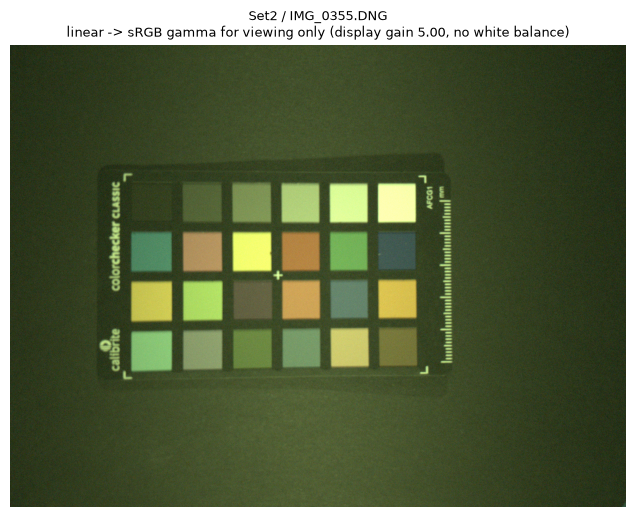

In [6]:
# convert to linear color (no demosaicing)

def raw_to_linear_quarter(path, saturation, verbose=True):
    with rawpy.imread(str(path)) as raw:
        # STEP 1: raw sensor values for the visible area only (no demosaic,
        # no white balance, no gamma). Copy because the view dies with the file.
        mosaic = raw.raw_image_visible.astype(np.float32)
 
        # STEP 2: read the mosaic layout FROM THE FILE.
        # raw_colors_visible gives, for every pixel, an index into color_desc
        # (e.g. b'RGBG': 0=R, 1=G, 2=B, 3=second G). It already accounts for
        # the crop to the visible area, so it lines up with raw_image_visible.
        colors = raw.raw_colors_visible.copy()
        letters = raw.color_desc.decode()          # e.g. "RGBG"
        black_per_color = np.array(raw.black_level_per_channel, dtype=np.float32)
 
    H, W = mosaic.shape
    H2, W2 = H // 2, W // 2                         # drop an odd last row/col if any
    mosaic, colors = mosaic[:2 * H2, :2 * W2], colors[:2 * H2, :2 * W2]
 
    # the 2x2 tile at the top-left, and a check that it repeats across the whole image
    tile = colors[:2, :2]
    for i in range(2):
        for j in range(2):
            assert np.all(colors[i::2, j::2] == tile[i, j]), \
                f"CFA pattern is not a clean repeating 2x2 tile (site {i},{j})"
    pattern = [[letters[tile[i, j]] for j in range(2)] for i in range(2)]
    pattern_str = "".join(pattern[0] + pattern[1])  # row-major, e.g. "RGGB"
 
    # STEP 3: subtract the black level (per site, using that site's colour) and
    # divide by the span from black up to saturation. Do NOT clip here:
    # noise makes dark pixels slightly negative, and clipping them to 0 would
    # bias the mean of a dark patch upward.
    black_map = black_per_color[colors]
    linear = (mosaic - black_map) / (saturation - black_map)
 
    # STEP 4: collapse every 2x2 block to one pixel, no interpolation.
    # Take each of the four sites in the tile and file it under its colour letter.
    planes = {"R": [], "G": [], "B": []}
    for i in range(2):
        for j in range(2):
            planes[pattern[i][j]].append(linear[i::2, j::2])   # shape (H2, W2)
    assert len(planes["R"]) == 1 and len(planes["B"]) == 1 and len(planes["G"]) == 2, \
        f"unexpected CFA layout: {pattern_str}"
 
    quarter = np.stack([planes["R"][0],
                        np.mean(planes["G"], axis=0),   # mean of the two green sites
                        planes["B"][0]], axis=-1)
 
    info = {"cfa_pattern": pattern_str, "cfa_tile": pattern,
            "color_desc": letters,
            "black_level": [float(b) for b in black_per_color],
            "saturation": saturation,
            "shape_mosaic": (2 * H2, 2 * W2), "shape_quarter": quarter.shape}
    if verbose:
        print(f"CFA pattern (row-major 2x2 tile): {pattern_str}   {pattern}")
        print(f"Black level per channel:          {info['black_level']}")
        print(f"Saturation value used:            {saturation}")
        print(f"Mosaic {info['shape_mosaic']} -> quarter-res {quarter.shape}")
        print(f"Linear range in quarter image:    min {quarter.min():.4f}, "
              f"max {quarter.max():.4f}")
    return quarter, info
 
 
def show_linear(quarter, display_gain=None, title=""):
    """DISPLAY ONLY. Measurements must use `quarter`, never this converted copy."""
    x = np.clip(quarter, 0, 1)
    if display_gain is None:                         # brighten dark captures for viewing
        display_gain = 1.0 / max(np.percentile(x, 99.5), 1e-6)
    x = np.clip(x * display_gain, 0, 1)
    srgb = np.where(x <= 0.0031308, 12.92 * x, 1.055 * x ** (1 / 2.4) - 0.055)
    plt.figure(figsize=(8, 6))
    plt.imshow(srgb)
    plt.title(f"{title}\nlinear -> sRGB gamma for viewing only "
              f"(display gain {display_gain:.2f}, no white balance)", fontsize=9)
    plt.axis("off")
    plt.show()

CAPTURE_ROOT = r"C:\Users\ammat\Documents\Assignment4 Captures"
SATURATION = 4095          # the clipping value you measured from the Set 1 histograms


folder = find_condition_folders(CAPTURE_ROOT)[1]
path = list_dngs(folder)[0]
quarter, info = raw_to_linear_quarter(path, SATURATION)
show_linear(quarter, title=f"{folder.name} / {path.name}")

3. Correct that capture for lens shading using the white sheet from the same round. Normalize the flat field to its own center and divide, treating each of the three channels separately rather than applying one gray correction. Then find out what you are correcting. Normalize the white sheet from every round the same way and plot a horizontal profile through the center of each on one axis. If the falloff belongs to the lamps it will differ from round to round; if it belongs to the lens it will not, because it is fixed to the frame rather than to the scene. That answer decides whether a flat field from one round can stand in for another, which is what rescues a round whose own white sheet is unusable.
Deliverable: The capture before and after correction; the ratio of a region at the corner of the frame to the same region at its center, measured on the white sheet itself, before and after; the profiles from all your rounds on one axis; and one sentence on what the comparison tells you.

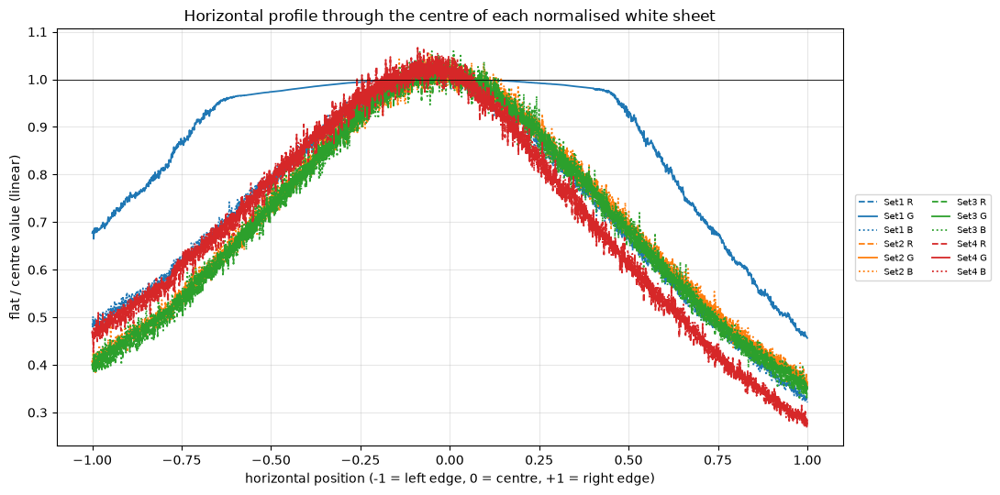

In [7]:

def normalize_flat(flat_q, frac=0.10):
    """Divide each channel by its own mean over the central `frac` of the image."""
    h, w, _ = flat_q.shape
    dy, dx = int(h * frac / 2), int(w * frac / 2) # <- size of center steps
    center = flat_q[h // 2 - dy:h // 2 + dy, w // 2 - dx:w // 2 + dx].mean(axis=(0, 1)) # <- get the center mean
    return flat_q / center, center            # return: image/mean(center), and that center patch mean

# Horizontal profile through the centre of every normalised white sheet, one axis.
# Needs from earlier cells: find_condition_folders, list_dngs,
# raw_to_linear_quarter, SATURATION, normalize_flat 

CAPTURE_ROOT = r"C:\Users\ammat\Documents\Assignment4 Captures"
ROW_BAND = 0.02            # average the middle 2% of rows (less noise than a single row)
CHANNELS = ["R", "G", "B"]
LINESTYLES = {"R": "--", "G": "-", "B": ":"}      # colour = set, line style = channel


# 1) normalised flat for every set (centre = 1 in each channel)
flat_norms = {}
for folder in find_condition_folders(CAPTURE_ROOT):
    flat_file = list_dngs(folder)[-1]               # last file = white field
    flat_q, _ = raw_to_linear_quarter(flat_file, SATURATION, verbose=False)
    flat_norms[folder.name], _ = normalize_flat(flat_q)


# 2) horizontal profile = mean of a thin band of rows around the centre row
def horizontal_profile(flat_norm, band=ROW_BAND):
    h = flat_norm.shape[0]
    half = max(int(h * band / 2), 1)
    return flat_norm[h // 2 - half:h // 2 + half].mean(axis=0)   # shape (W, 3)


# 3) one axis, all sets and channels
fig, ax = plt.subplots(figsize=(11, 5.5))
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for s, (name, fn) in enumerate(flat_norms.items()):
    prof = horizontal_profile(fn)
    x = np.linspace(-1, 1, prof.shape[0])           # -1 = left edge, +1 = right edge
    for k, ch in enumerate(CHANNELS):
        ax.plot(x, prof[:, k], color=colors[s % len(colors)],
                ls=LINESTYLES[ch], lw=1.3, label=f"{name} {ch}")

ax.axhline(1.0, color="k", lw=0.6)
ax.set_xlabel("horizontal position (-1 = left edge, 0 = centre, +1 = right edge)")
ax.set_ylabel("flat / centre value (linear)")
ax.set_title("Horizontal profile through the centre of each normalised white sheet")
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()


If we look at the plot of the profiles of the horizontal lines through the center, we see what looks like clipping on the green channel from the first set, we also see that the fourth set is different to, while the 2nd & 3rd sets lay on top of each other. This tells us we should use the use the 2nd and 3rd sets for the lens correction as these do not clip and should be the true effect of the lens, this makes sense give the lighting condtions (set 1 clipping, and set 4 was ouside). For the lens correction I will average each channel from 2nd and 3rd set, both line up and this should help with reducing noise effects. 

Wait can we use the white capture from the 2nd and 3rd on the 4th, the 4th one outside had a different aperture setting. Would this effect the lens capture effect.

('Set4',) R: fit RMS = 0.0783
('Set4',) G: fit RMS = 0.0356
('Set4',) B: fit RMS = 0.0577
('Set2', 'Set3') R: fit RMS = 0.0396
('Set2', 'Set3') G: fit RMS = 0.0249
('Set2', 'Set3') B: fit RMS = 0.0617


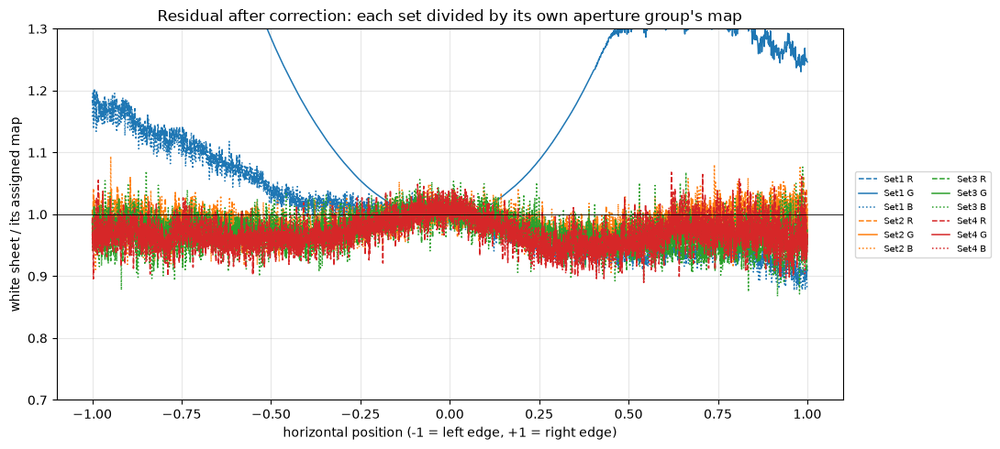

In [8]:
# One lens map per aperture group, applied to the matching sets.
# Needs from earlier cells: flat_norms, fit_surface, horizontal_profile,
# find_condition_folders, list_dngs, raw_to_linear_quarter, SATURATION, CAPTURE_ROOT

# Which white sheet(s) provide the lens map for each set.
# Sets that share an aperture share a map; Set 4 (different aperture) uses its own.
# EDIT Set1 if it was shot at a different aperture from Sets 2 and 3.

DEGREE = 6                      # polynomial order of the smooth surface
STEP = 8  
FLAT_SOURCE = {
    "Set1": ("Set2", "Set3"),
    "Set2": ("Set2", "Set3"),
    "Set3": ("Set2", "Set3"),
    "Set4": ("Set4",),
}

def fit_surface(img2d, deg=DEGREE, step=STEP):
    """Least-squares 2D polynomial fit; returns the full-size smooth surface + fit RMS."""
    h, w = img2d.shape
    y = np.linspace(-1, 1, h, dtype=np.float32)
    x = np.linspace(-1, 1, w, dtype=np.float32)
    terms = [(i, j) for i in range(deg + 1) for j in range(deg + 1 - i)]
 
    Ys, Xs = np.meshgrid(y[::step], x[::step], indexing="ij")
    A = np.stack([(Xs ** i * Ys ** j).ravel() for i, j in terms], axis=1)
    target = img2d[::step, ::step].ravel()
    coef, *_ = np.linalg.lstsq(A, target, rcond=None)
    rms = float(np.sqrt(np.mean((A @ coef - target) ** 2)))
 
    Yf, Xf = np.meshgrid(y, x, indexing="ij")
    surf = np.zeros((h, w), dtype=np.float32)
    for c, (i, j) in zip(coef, terms):
        surf += np.float32(c) * (Xf ** i * Yf ** j)
    return surf, rms
 

def build_master(set_names):
    """Average the named normalised flats, smooth each channel, centre = 1."""
    mean_flat = np.mean([flat_norms[s] for s in set_names], axis=0)
    master = np.empty_like(mean_flat, dtype=np.float32)
    for k in range(3):
        surf, rms = fit_surface(mean_flat[..., k])
        h, w = surf.shape
        dy, dx = int(h * 0.05), int(w * 0.05)
        surf /= surf[h // 2 - dy:h // 2 + dy, w // 2 - dx:w // 2 + dx].mean()
        master[..., k] = surf
        print(f"{set_names} {'RGB'[k]}: fit RMS = {rms:.4f}")
    return master


masters = {src: build_master(src) for src in set(FLAT_SOURCE.values())}

# apply each set's assigned map to its charts (4th file = white field)
lens_corrected = {}
for folder in find_condition_folders(CAPTURE_ROOT):
    master = masters[FLAT_SOURCE[folder.name]]
    *charts, _ = list_dngs(folder)
    for f in charts:
        img_q, _ = raw_to_linear_quarter(f, SATURATION, verbose=False)
        lens_corrected[(folder.name, f.name)] = img_q / np.maximum(master, 0.05)

# check: each set's white sheet divided by the map it was given
fig, ax = plt.subplots(figsize=(11, 5))
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
styles = {"R": "--", "G": "-", "B": ":"}
for s, (name, fn) in enumerate(flat_norms.items()):
    prof = horizontal_profile(fn / masters[FLAT_SOURCE[name]])
    x = np.linspace(-1, 1, prof.shape[0])
    for k, ch in enumerate("RGB"):
        ax.plot(x, prof[:, k], color=colors[s % len(colors)], ls=styles[ch],
                lw=1.1, label=f"{name} {ch}")
ax.axhline(1.0, color="k", lw=0.6)
ax.set_ylim(0.7, 1.3)
ax.set_xlabel("horizontal position (-1 = left edge, +1 = right edge)")
ax.set_ylabel("white sheet / its assigned map")
ax.set_title("Residual after correction: each set divided by its own aperture group's map")
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()


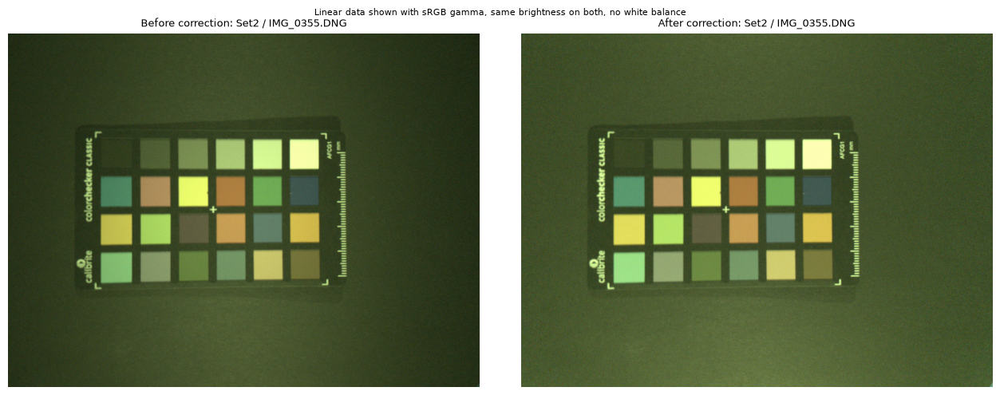

,set,channel,before,after
0,Set1,R,0.318,1.049
1,Set1,G,0.453,1.467
2,Set1,B,0.326,1.046
3,Set2,R,0.313,1.036
4,Set2,G,0.313,1.020
5,Set2,B,0.319,1.029
6,Set3,R,0.298,0.987
7,Set3,G,0.308,1.004
8,Set3,B,0.311,1.003
9,Set4,R,0.301,1.050


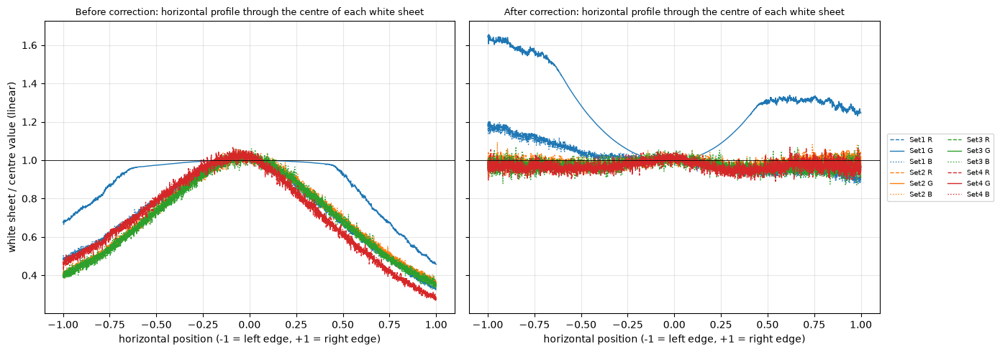


On the white sheets the corner-to-centre ratio goes from 0.30-0.33 before correction to 0.99-1.05 after, so the correction removes most of the lens falloff, leaving the sheets uniform to within about 5% (Set 1 green excluded because its sheet is clipped).


In [9]:
# Before/after report for the lens correction.
# Needs from earlier cells: flat_norms, masters, FLAT_SOURCE, lens_corrected,
# horizontal_profile, raw_to_linear_quarter, find_condition_folders, list_dngs,
# SATURATION, CAPTURE_ROOT   (run lens_master_per_aperture.py first).

SHOW_SET = "Set2"          # which set's chart to show before/after
SHOW_CHART = 0             # 0 = chart 1, 1 = chart 2, 2 = chart 3
REGION_FRAC = 0.05         # corner and centre regions are each 5% of height x 5% of width
CHANNELS = ["R", "G", "B"]


# ---------- 1) one capture, before and after (same display brightness) ----------
folder = next(f for f in find_condition_folders(CAPTURE_ROOT) if f.name == SHOW_SET)
chart_file = list_dngs(folder)[SHOW_CHART]
before_img, _ = raw_to_linear_quarter(chart_file, SATURATION, verbose=False)
after_img = lens_corrected[(SHOW_SET, chart_file.name)]


def to_display(x, gain):                         # linear -> sRGB, for viewing only
    x = np.clip(x * gain, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * x ** (1 / 2.4) - 0.055)


gain = 1.0 / max(np.percentile(np.clip(after_img, 0, 1), 99.5), 1e-6)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, img, title in zip(axes, (before_img, after_img), ("Before correction", "After correction")):
    ax.imshow(to_display(img, gain))
    ax.set_title(f"{title}: {SHOW_SET} / {chart_file.name}", fontsize=9)
    ax.axis("off")
fig.suptitle("Linear data shown with sRGB gamma, same brightness on both, no white balance",
             fontsize=8)
fig.tight_layout()
plt.show()


# ---------- 2) corner / centre ratio on each white sheet, before and after ----------
def corner_over_center(img):
    """Mean of the four corner regions divided by the centre region (same size), per channel."""
    h, w, _ = img.shape
    ch, cw = max(int(h * REGION_FRAC), 1), max(int(w * REGION_FRAC), 1)
    corners = [img[:ch, :cw], img[:ch, -cw:], img[-ch:, :cw], img[-ch:, -cw:]]
    corner = np.mean([c.reshape(-1, 3).mean(axis=0) for c in corners], axis=0)
    cy, cx = h // 2, w // 2
    center = img[cy - ch // 2:cy + ch // 2, cx - cw // 2:cx + cw // 2].reshape(-1, 3).mean(axis=0)
    return corner / center


flats_after = {n: fn / np.maximum(masters[FLAT_SOURCE[n]], 0.05) for n, fn in flat_norms.items()}

rows = []
for name in flat_norms:
    b, a = corner_over_center(flat_norms[name]), corner_over_center(flats_after[name])
    for k, ch in enumerate(CHANNELS):
        rows.append({"set": name, "channel": ch, "before": b[k], "after": a[k]})
ratio_df = pd.DataFrame(rows)
display(ratio_df.round(3))


# ---------- 3) profiles from all rounds on one axis, before and after ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
styles = {"R": "--", "G": "-", "B": ":"}
for ax, flats, title in zip(axes, (flat_norms, flats_after), ("Before correction", "After correction")):
    for s, (name, fn) in enumerate(flats.items()):
        prof = horizontal_profile(fn)
        x = np.linspace(-1, 1, prof.shape[0])
        for k, ch in enumerate(CHANNELS):
            ax.plot(x, prof[:, k], color=colors[s % len(colors)], ls=styles[ch],
                    lw=1.0, label=f"{name} {ch}")
    ax.axhline(1.0, color="k", lw=0.6)
    ax.set_title(f"{title}: horizontal profile through the centre of each white sheet", fontsize=9)
    ax.set_xlabel("horizontal position (-1 = left edge, +1 = right edge)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("white sheet / centre value (linear)")
axes[1].legend(ncol=2, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()


# ---------- 4) one sentence, built from the numbers ----------
# Set1 green is left out: its white sheet is clipped, so its ratios are not trustworthy.
valid = ratio_df[~((ratio_df["set"] == "Set1") & (ratio_df["channel"] == "G"))]
b, a = valid["before"].to_numpy(), valid["after"].to_numpy()
worst = 100 * np.max(np.abs(a - 1))
print(f"\nOn the white sheets the corner-to-centre ratio goes from {b.min():.2f}-{b.max():.2f} "
      f"before correction to {a.min():.2f}-{a.max():.2f} after, so the correction removes "
      f"{'nearly all' if worst < 5 else 'most'} of the lens falloff, leaving the sheets "
      f"uniform to within about {worst:.0f}% (Set 1 green excluded because its sheet is clipped).")

We lose the dark shading around the edge whicg tells me that we are correcting the vinetting lens effect, this seems to work very well for the charts that do not exhibit clipping.

4. Locate the twenty four patches and extract their mean linear RGB. Sample well inside each patch, no more than the middle half of it, so that the black separators and any edge artifacts stay out of the average.
Deliverable: A figure showing the regions you sampled drawn on the chart, and your 24 by 3 table of patch means.

In [10]:

PATCH_NAMES = [
    "dark skin", "light skin", "blue sky", "foliage", "blue flower", "bluish green",
    "orange", "purplish blue", "moderate red", "purple", "yellow green", "orange yellow",
    "blue", "green", "red", "yellow", "magenta", "cyan",
    "white", "neutral 8", "neutral 6.5", "neutral 5", "neutral 3.5", "black",
]
GRID_COLS, GRID_ROWS = 6, 4        # 24-patch chart: 6 columns x 4 rows
CORE = 0.40                        # sample the central 40% (never more than half) of each patch


def _to_display_rgb8(linear_rgb):
    """Linear -> brightened 8-bit sRGB copy. Used ONLY for detection and for drawing."""
    x = np.clip(linear_rgb, 0, 1)
    x = np.clip(x / max(np.percentile(x, 99.5), 1e-6), 0, 1)
    srgb = np.where(x <= 0.0031308, 12.92 * x, 1.055 * x ** (1 / 2.4) - 0.055)
    return np.ascontiguousarray((srgb * 255 + 0.5).astype(np.uint8))


def sample_patch_means(img, corners, core=CORE):
    """Mean / std of the central part of each of the 24 patches, in the ORIGINAL (linear) img.

    corners: 4x2 outer corners of the patch grid, order top-left, top-right, bottom-right,
    bottom-left as the chart reads. A homography maps the 6x4 grid onto them, so tilted
    or rotated charts work. `core` is the fraction of each patch side that is sampled.
    """
    assert 0 < core <= 0.5, "sample at most the middle half of each patch"
    unit = np.float32([[0, 0], [GRID_COLS, 0], [GRID_COLS, GRID_ROWS], [0, GRID_ROWS]])
    M = cv2.getPerspectiveTransform(unit, np.float32(corners))
    h, w = img.shape[:2]
    means, stds, clipped, counts, polys = [], [], [], [], []
    for r in range(GRID_ROWS):
        for c in range(GRID_COLS):
            cx, cy, d = c + 0.5, r + 0.5, core / 2
            q = np.float32([[cx - d, cy - d], [cx + d, cy - d], [cx + d, cy + d], [cx - d, cy + d]])
            poly = cv2.perspectiveTransform(q[None], M)[0]
            pts = np.round(poly).astype(np.int32)
            x, y, bw, bh = cv2.boundingRect(pts)
            if x < 0 or y < 0 or x + bw > w or y + bh > h:
                raise ValueError(f"patch {len(means) + 1} falls outside the image")
            mask = np.zeros((bh, bw), np.uint8)
            cv2.fillConvexPoly(mask, pts - np.array([x, y], dtype=np.int32), 1)
            px = img[y:y + bh, x:x + bw][mask.astype(bool)].astype(np.float64)
            means.append(px.mean(axis=0))
            stds.append(px.std(axis=0))
            clipped.append(float((px >= 0.999).any(axis=1).mean()))
            counts.append(len(px))
            polys.append(poly)
    return (np.array(means), np.array(stds), np.array(clipped), np.array(counts), polys)


def _run_mcc_detector(bgr8):
    """Run cv2.mcc for the 24-patch chart on an 8-bit BGR image, across OpenCV versions.

    OpenCV 4.x:  process(image, chartType, nc)
    OpenCV 5.x:  chart type is a setting (setColorChartType) and process(image[, nc])
    Returns (detector, found).
    """
    mcc24 = getattr(cv2.mcc, "MCC24", 0)
    make = getattr(cv2.mcc, "CCheckerDetector_create", None) or cv2.mcc.CCheckerDetector.create
    det = make()
    if hasattr(det, "setColorChartType"):
        try:
            det.setColorChartType(mcc24)
        except Exception:
            pass
    errors = []
    for call in (lambda: det.process(bgr8, mcc24, 1),       # OpenCV 4.x signature
                 lambda: det.process(bgr8, 1)):             # OpenCV 5.x signature
        try:
            return det, bool(call())
        except cv2.error as e:
            errors.append(str(e).strip().splitlines()[0])
    raise RuntimeError("cv2.mcc process() failed with both signatures: " + " | ".join(errors))


def find_colorchecker(linear_rgb, corners=None, core=CORE):
    """Locate the 24 patches and measure their mean linear RGB.

    corners: optional manual outer corners (TL, TR, BR, BL); if None the cv2.mcc detector
    is used on an 8-bit display copy. The linear image is what actually gets measured.
    Returns a dict: means (24,3), stds, clipped_frac, n_pixels, polys, corners,
    orientation_rms (detector agreement, 8-bit counts; nan for manual corners),
    grey_ramp_ok (patches 19..24 get darker).
    """
    rgb8 = _to_display_rgb8(linear_rgb)
    orientation_rms = float("nan")

    if corners is None:
        det, found = _run_mcc_detector(np.ascontiguousarray(rgb8[..., ::-1]))
        if not found:
            raise RuntimeError("no 24-patch chart found; pass corners=[TL, TR, BR, BL] manually")
        checker = det.getBestColorChecker()
        box = np.asarray(checker.getBox(), dtype=np.float32).reshape(4, 2)

        # The detector's own patch means (8-bit RGB), used to verify the corner order.
        try:
            ref = np.asarray(checker.getChartsRGB())[:, 1].reshape(-1, 3)
            assert len(ref) == 24
        except Exception:
            ref = None

        if ref is None:
            print("[warn] could not read the detector's patch colours; orientation is NOT "
                  "verified. Check the figure and the grey-ramp line carefully.")
            corners = box
        else:
            # Corner order from the detector is not guaranteed: try 4 rotations and the
            # reversed winding, keep the one whose patch colours match the detector's own.
            best = None
            for pts in (box, box[::-1]):
                for s in range(4):
                    cand = np.roll(pts, -s, axis=0)
                    m, *_ = sample_patch_means(rgb8, cand, core)
                    err = float(np.sqrt(np.mean((m - ref) ** 2)))
                    if best is None or err < best[1]:
                        best = (cand, err)
            corners, orientation_rms = best

    corners = np.float32(corners)
    means, stds, clipped, counts, polys = sample_patch_means(linear_rgb, corners, core)
    lum = means @ np.array([0.2126, 0.7152, 0.0722])
    return {"means": means, "stds": stds, "clipped_frac": clipped, "n_pixels": counts,
            "polys": polys, "corners": corners, "orientation_rms": orientation_rms,
            "grey_ramp_ok": bool(np.all(np.diff(lum[18:24]) < 0)), "core": core}


def plot_sampled_regions(linear_rgb, result, title="", save=None):
    """Draw the sampled regions (yellow, numbered) and chart outline (cyan) on the chart."""
    rgb8 = _to_display_rgb8(linear_rgb)
    corners = result["corners"]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(rgb8)
    ax.add_patch(plt.Polygon(corners, closed=True, fill=False, ec="cyan", lw=1.5, ls="--"))
    for i, poly in enumerate(result["polys"]):
        ax.add_patch(plt.Polygon(poly, closed=True, fill=False, ec="yellow", lw=1.3))
        ax.text(*poly.mean(axis=0), str(i + 1), color="yellow", ha="center", va="center",
                fontsize=9, fontweight="bold")
    (x0, y0), (x1, y1) = corners.min(axis=0), corners.max(axis=0)
    m = 0.05 * max(x1 - x0, y1 - y0)
    h, w = rgb8.shape[:2]
    ax.set_xlim(max(x0 - m, 0), min(x1 + m, w))
    ax.set_ylim(min(y1 + m, h), max(y0 - m, 0))
    ax.set_title(f"{title}\nyellow = sampled regions (central {result['core']:.0%} of each patch), "
                 f"cyan = detected chart outline", fontsize=9)
    ax.axis("off")
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=200)
    return fig


def patch_table(result):
    """24 x 3 DataFrame of mean linear R, G, B (black-subtracted, 1.0 = saturation)."""
    t = pd.DataFrame(result["means"], columns=["R", "G", "B"],
                     index=[f"{i + 1} {n}" for i, n in enumerate(PATCH_NAMES)])
    t.index.name = "patch"
    return t

Set2 / IMG_0355.DNG
  orientation check RMS vs detector: 0.1 / 255 (small = good)
  grey row 19->24 gets darker:       True
  pixels per patch:                  3999 to 4936


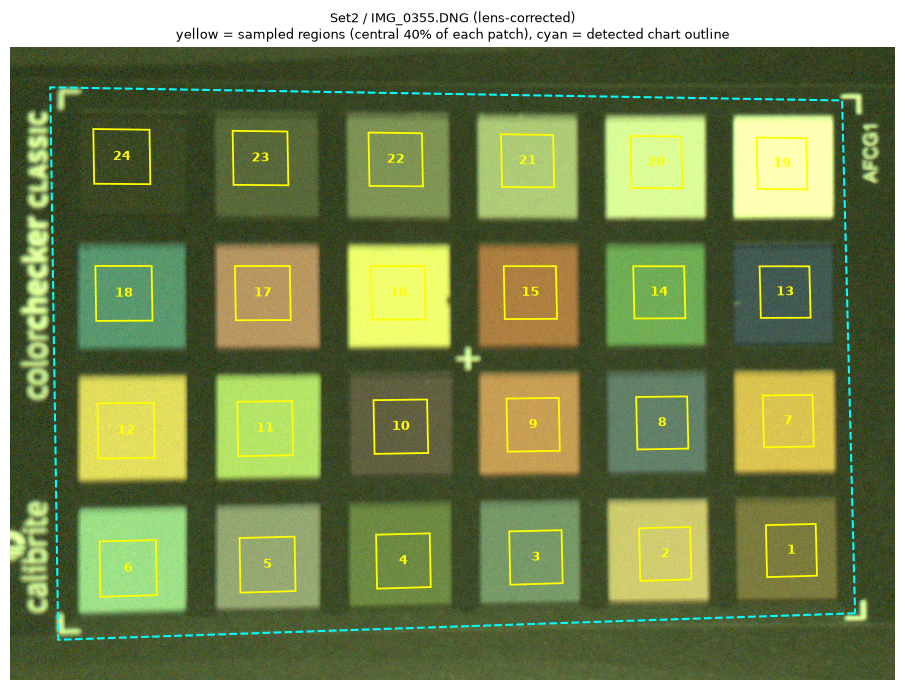

,R,G,B
patch,,,
1 dark skin,0.0442,0.0446,0.0111
2 light skin,0.1389,0.1339,0.0356
3 blue sky,0.0411,0.0710,0.0306
4 foliage,0.0345,0.0565,0.0130
5 blue flower,0.0667,0.0868,0.0380
6 bluish green,0.0752,0.1660,0.0532
7 orange,0.1572,0.1208,0.0184
8 purplish blue,0.0278,0.0485,0.0312
9 moderate red,0.1270,0.0760,0.0198


In [11]:

# First capture of Set 2, taken from the lens-corrected images (`lens_corrected` dict).
key = sorted(k for k in lens_corrected if k[0] == "Set2")[0]
img = lens_corrected[key]

result = find_colorchecker(img)

print(f"{key[0]} / {key[1]}")
print(f"  orientation check RMS vs detector: {result['orientation_rms']:.1f} / 255 "
      f"(small = good)")
print(f"  grey row 19->24 gets darker:       {result['grey_ramp_ok']}")
print(f"  pixels per patch:                  {result['n_pixels'].min()} to {result['n_pixels'].max()}")
if result["clipped_frac"].max() > 0:
    print(f"  [warn] clipped pixels inside sampled regions (max {result['clipped_frac'].max():.1%})")

plot_sampled_regions(img, result, title=f"{key[0]} / {key[1]} (lens-corrected)",
                     save="patch_regions.png")
plt.show()

table = patch_table(result)
display(table.round(4))
table.to_csv("patch_means.csv")

The color chart and the labels match up.

### Part 2: White balance and the color matrix

5. Fit the white balance gains from the neutral patches, which are patches 19 through 24 of the reference set, and apply them to all twenty four. Before you do, confirm that your patch numbering matches that set, whose first patch is dark skin and whose nineteenth is white. A chart photographed upside down or on its side still fills the frame with twenty four patches, and indexing them from the corner of the image without checking will silently pair every measurement with the wrong reference value. Set the gains from an unclipped mid gray patch rather than from the white one. White is the brightest patch on the chart and so the first to clip, and gains fitted to a clipped patch are wrong in a way that nothing downstream will reveal. A neutral surface should produce equal camera RGB, and the gains are whatever makes that true.
Deliverable: The three gains, normalized to the green channel, and the patch means after balancing.

Set2 / IMG_0355.DNG
  orientation check RMS vs detector: 0.1/255 (small = good);  grey row 19->24 gets darker: True
  clipped patches (excluded): none;  clipped pixels in the whole image: 0.000%


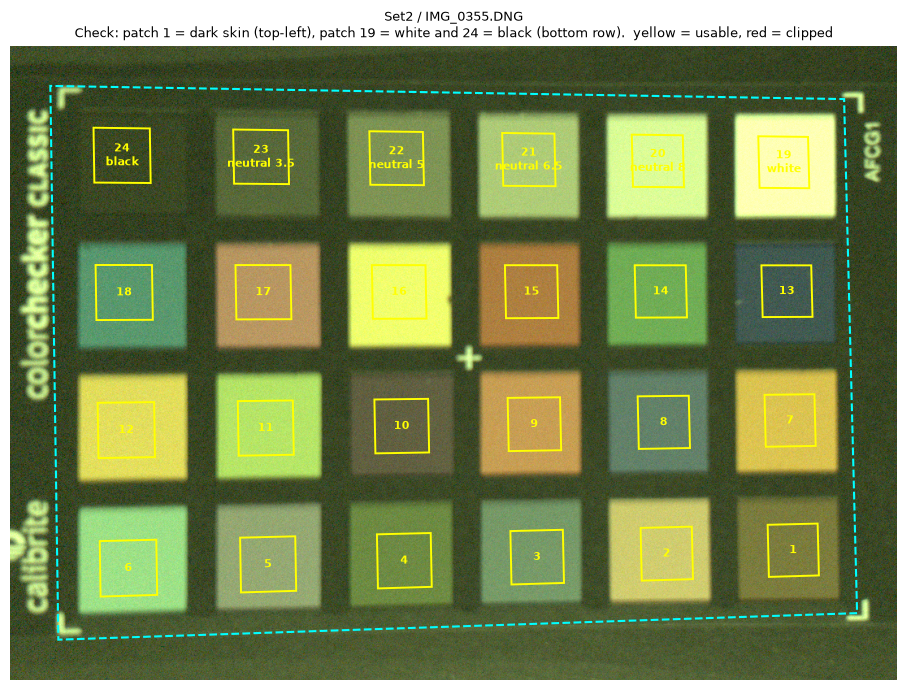


Gains from each neutral patch (green = 1):


,patch,name,R,G,B,gain_R (G/R),gain_B (G/B),clipped,used
0,19,white,0.2399,0.3298,0.1001,1.3747,3.2944,False,True
1,20,neutral 8,0.1571,0.2197,0.0679,1.3985,3.2384,False,True
2,21,neutral 6.5,0.0934,0.1323,0.0410,1.4168,3.2230,False,True
3,22,neutral 5,0.0463,0.0649,0.0201,1.4018,3.2212,False,True
4,23,neutral 3.5,0.0219,0.0307,0.0097,1.4073,3.1571,False,True


  spread between usable patches: R 3.0%, B 4.3%
  [warn] spread above 3%: check black level, flare, clipping, or a mislocated patch before trusting these gains


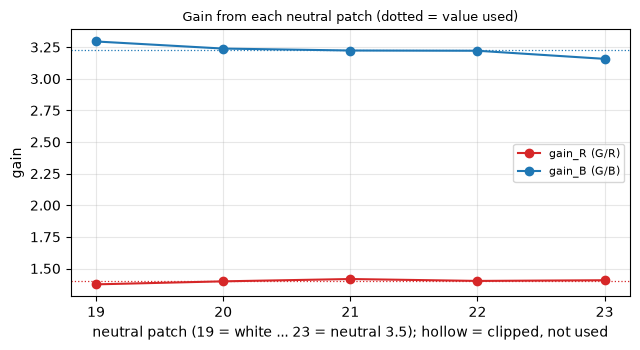


White balance gains (normalised to green):  R = 1.3998   G = 1.0000   B = 3.2268
Camera's own as-shot gains from the DNG:    R = 1.5366   G = 1.0000   B = 2.7256

Patch means after white balance (neutral patches 19-24 should have R/G and B/G near 1):


,R,G,B,R/G,B/G,clipped
patch,,,,,,
1 dark skin,0.0619,0.0446,0.0359,1.3883,0.8060,False
2 light skin,0.1944,0.1339,0.1149,1.4523,0.8583,False
3 blue sky,0.0575,0.0710,0.0988,0.8110,1.3925,False
4 foliage,0.0483,0.0565,0.0419,0.8555,0.7408,False
5 blue flower,0.0933,0.0868,0.1225,1.0751,1.4108,False
6 bluish green,0.1053,0.1660,0.1715,0.6344,1.0332,False
7 orange,0.2201,0.1208,0.0593,1.8213,0.4910,False
8 purplish blue,0.0389,0.0485,0.1007,0.8028,2.0779,False
9 moderate red,0.1777,0.0760,0.0640,2.3380,0.8423,False


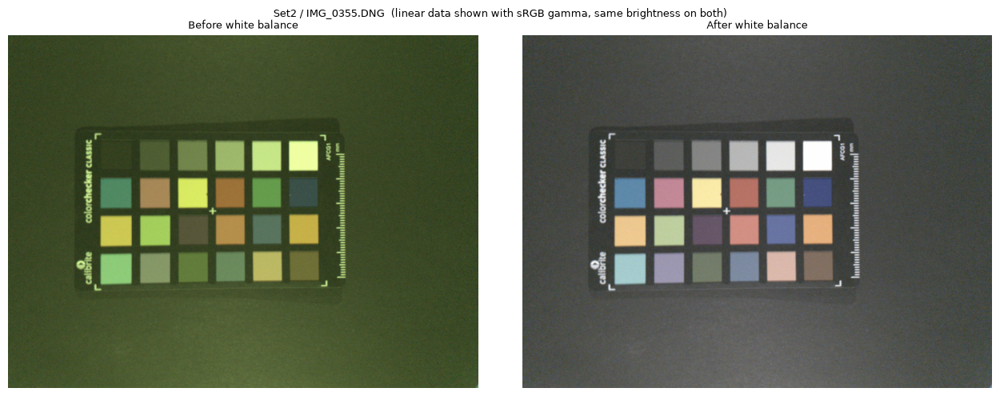

In [12]:
# we need to get the mean rgb of the 19-24. THen compute gains (r = g/r, b = g/b, g stays at 1). Check that the gain
# values are consstent across the series of grey patches. Then apply the gain to all 24 patches

# constants and settings:
NEUTRAL_PATCHES = (19, 20, 21, 22, 23)  # 1-based; white .. neutral 3.5. Patch 24 (black) is
                                        # left out: mostly noise and flare.
CLIP_LEVEL = 0.98       # a pixel with any channel >= this (raw, before lens correction) is clipped
CLIP_FRAC_MAX = 0.001   # a patch with more than 0.1% clipped pixels is NOT used
SPREAD_WARN = 0.03      # warn if the per-patch gains disagree by more than 3%

# initail steps: subtract dark level offset:

# find patches; and display the labeled patches to catch if they are off

def plot_labeled_patches(img, result, clipped, title=""):
    """Check 1: are the right patches found? Numbered regions on the chart.
    Yellow = usable, red = clipped (excluded). Grey-row patches also show their names."""
    rgb8 = _to_display_rgb8(img)
    corners = result["corners"]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(rgb8)
    ax.add_patch(plt.Polygon(corners, closed=True, fill=False, ec="cyan", lw=1.5, ls="--"))
    for i, poly in enumerate(result["polys"]):
        color = "red" if clipped[i] else "yellow"
        ax.add_patch(plt.Polygon(poly, closed=True, fill=False, ec=color, lw=1.4))
        label = str(i + 1) + (f"\n{PATCH_NAMES[i]}" if i >= 18 else "")
        ax.text(*poly.mean(axis=0), label, color=color, ha="center", va="center",
                fontsize=8, fontweight="bold")
    (x0, y0), (x1, y1) = corners.min(axis=0), corners.max(axis=0)
    m = 0.05 * max(x1 - x0, y1 - y0)
    h, w = rgb8.shape[:2]
    ax.set_xlim(max(x0 - m, 0), min(x1 + m, w))
    ax.set_ylim(min(y1 + m, h), max(y0 - m, 0))
    ax.set_title(f"{title}\nCheck: patch 1 = dark skin (top-left), patch 19 = white and 24 = black "
                 f"(bottom row).  yellow = usable, red = clipped", fontsize=9)
    ax.axis("off")
    fig.tight_layout()
    return fig
 
# check if patches are clipping

def patch_clipped_fraction(img, polys, level=CLIP_LEVEL):
    """Fraction of pixels inside each sampled patch region with any channel >= level.
    Pass the image BEFORE lens correction: the lens map multiplies edge pixels by >1, which
    would make unclipped pixels look clipped."""
    out = []
    for poly in polys:
        pts = np.round(poly).astype(np.int32)
        x, y, bw, bh = cv2.boundingRect(pts)
        mask = np.zeros((bh, bw), np.uint8)
        cv2.fillConvexPoly(mask, pts - np.array([x, y], dtype=np.int32), 1)
        px = img[y:y + bh, x:x + bw][mask.astype(bool)]
        out.append(float((px >= level).any(axis=1).mean()))
    return np.array(out)


def neutral_gain_table(result, clipped, neutral=NEUTRAL_PATCHES):
    """Per-patch white-balance gains from the neutral patches (green is the anchor)."""
    idx = [p - 1 for p in neutral]
    m = result["means"][idx]
    tbl = pd.DataFrame({
        "patch": list(neutral),
        "name": [PATCH_NAMES[i] for i in idx],
        "R": m[:, 0], "G": m[:, 1], "B": m[:, 2],
        "gain_R (G/R)": m[:, 1] / m[:, 0],
        "gain_B (G/B)": m[:, 1] / m[:, 2],
        "clipped": clipped[idx],
    })
    tbl["used"] = ~tbl["clipped"]
    return tbl
 
 
def combine_gains(tbl):
    """One (R, G, B) gain triple from the usable neutral patches, plus their spread."""
    use = tbl[tbl["used"]]
    if use.empty:
        raise RuntimeError("every neutral patch is clipped; cannot compute white balance")
    gr, gb = use["gain_R (G/R)"], use["gain_B (G/B)"]
    gains = np.array([gr.mean(), 1.0, gb.mean()])
    spread = {"R": float((gr.max() - gr.min()) / gr.mean()),
              "B": float((gb.max() - gb.min()) / gb.mean())}
    return gains, spread
 
 
def plot_neutral_gains(tbl, gains):
    """Check 2: the gains from each neutral patch should agree (flat lines)."""
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    for col, color in (("gain_R (G/R)", "tab:red"), ("gain_B (G/B)", "tab:blue")):
        ok = tbl["used"]
        ax.plot(tbl.loc[ok, "patch"], tbl.loc[ok, col], "o-", color=color, label=col)
        ax.plot(tbl.loc[~ok, "patch"], tbl.loc[~ok, col], "o", mfc="none", color=color)
    ax.axhline(gains[0], color="tab:red", ls=":", lw=0.9)
    ax.axhline(gains[2], color="tab:blue", ls=":", lw=0.9)
    ax.set_xticks(tbl["patch"])
    ax.set_xlabel("neutral patch (19 = white ... 23 = neutral 3.5); hollow = clipped, not used")
    ax.set_ylabel("gain")
    ax.set_title("Gain from each neutral patch (dotted = value used)", fontsize=9)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig
 
 
def apply_gains(img, gains):
    """Multiply the R, G, B channels of a linear image by the gains (no clipping)."""
    return (img * np.asarray(gains, dtype=np.float32)).astype(np.float32)
 
 
def show_before_after(before, after, title=""):
    """Check 3: the corrected image next to the original, same display brightness."""
    gain = 1.0 / max(np.percentile(np.clip(after, 0, 1), 99.5), 1e-6)
 
    def disp(x):
        x = np.clip(x * gain, 0, 1)
        return np.where(x <= 0.0031308, 12.92 * x, 1.055 * x ** (1 / 2.4) - 0.055)
 
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, im, t in zip(axes, (before, after), ("Before white balance", "After white balance")):
        ax.imshow(disp(im))
        ax.set_title(t, fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{title}  (linear data shown with sRGB gamma, same brightness on both)", fontsize=9)
    fig.tight_layout()
    return fig
 
 
def camera_wb_gains(path):
    """The camera's own as-shot gains from the DNG, normalised to green (for comparison)."""
    try:
        with rawpy.imread(str(path)) as raw:
            cam = np.array(raw.camera_whitebalance, dtype=np.float64)
            letters = raw.color_desc.decode()
        r, g, b = cam[letters.index("R")], cam[letters.index("G")], cam[letters.index("B")]
        return np.array([r / g, 1.0, b / g]) if g > 0 else None
    except Exception:
        return None
 
 
def white_balance_chart(img, uncorrected=None, title="", neutral=NEUTRAL_PATCHES,
                        camera_gains=None):
    """White balance one chart image from its neutral patches.
 
    img          lens-corrected linear RGB image (what gets measured and balanced)
    uncorrected  the same capture BEFORE lens correction, used only for the clipping tests
    camera_gains optional (R, G, B) gains from the DNG, printed for comparison
    Returns a dict: gains, balanced image, balanced patch means, clipped flags, tables.
    """
    # 1) find the patches and show them labelled
    result = find_colorchecker(img)
    print(f"{title}\n  orientation check RMS vs detector: {result['orientation_rms']:.1f}/255 "
          f"(small = good);  grey row 19->24 gets darker: {result['grey_ramp_ok']}")
 
    # 2) clipping: tested on the image before lens correction
    clip_img = uncorrected if uncorrected is not None else img
    if uncorrected is None:
        print("  [warn] no uncorrected image given: clipping is tested on the lens-corrected "
              "image, which can flag edge patches wrongly")
    frac = patch_clipped_fraction(clip_img, result["polys"])
    clipped = frac > CLIP_FRAC_MAX
    pixel_clip = (clip_img >= CLIP_LEVEL).any(axis=2)
    print(f"  clipped patches (excluded): {[int(i) + 1 for i in np.where(clipped)[0]] or 'none'};  "
          f"clipped pixels in the whole image: {pixel_clip.mean():.3%}")
    plot_labeled_patches(img, result, clipped, title)
    plt.show()
 
    # 3) gains from each neutral patch, and are they consistent?
    tbl = neutral_gain_table(result, clipped, neutral)
    gains, spread = combine_gains(tbl)
    print("\nGains from each neutral patch (green = 1):")
    display(tbl.round(4))
    print(f"  spread between usable patches: R {spread['R']:.1%}, B {spread['B']:.1%}")
    if max(spread.values()) > SPREAD_WARN:
        print(f"  [warn] spread above {SPREAD_WARN:.0%}: check black level, flare, clipping, "
              f"or a mislocated patch before trusting these gains")
    plot_neutral_gains(tbl, gains)
    plt.show()
 
    # 4) the gains, normalised to green
    g = gains / gains[1]
    print(f"\nWhite balance gains (normalised to green):  R = {g[0]:.4f}   G = {g[1]:.4f}   "
          f"B = {g[2]:.4f}")
    if camera_gains is not None:
        print(f"Camera's own as-shot gains from the DNG:    R = {camera_gains[0]:.4f}   "
              f"G = {camera_gains[1]:.4f}   B = {camera_gains[2]:.4f}")
 
    # 5) balanced patch means (multiplying the means equals measuring the balanced image)
    balanced_means = result["means"] * g
    out = pd.DataFrame(balanced_means, columns=["R", "G", "B"],
                       index=[f"{i + 1} {n}" for i, n in enumerate(PATCH_NAMES)])
    out["R/G"] = out["R"] / out["G"]
    out["B/G"] = out["B"] / out["G"]
    out["clipped"] = clipped
    out.index.name = "patch"
    print("\nPatch means after white balance (neutral patches 19-24 should have R/G and B/G near 1):")
    display(out.round(4))
 
    # 6) view the corrected image
    balanced = apply_gains(img, g)
    show_before_after(img, balanced, title)
    plt.show()
 
    return {"gains": g, "balanced": balanced, "balanced_means": balanced_means,
            "result": result, "clipped": clipped, "pixel_clip_mask": pixel_clip,
            "neutral_table": tbl, "balanced_table": out}

# RUN:
key = sorted(k for k in lens_corrected if k[0] == "Set2")[0]
folder = next(f for f in find_condition_folders(CAPTURE_ROOT) if f.name == key[0])
path = next(p for p in list_dngs(folder) if p.name == key[1])
uncorrected, _ = raw_to_linear_quarter(path, SATURATION, verbose=False)
 
wb = white_balance_chart(lens_corrected[key], uncorrected,
                         title=f"{key[0]} / {key[1]}",
                         camera_gains=camera_wb_gains(path))
 

Looking a the neutrals mean r g b values they all look close for each of the captures. Preliminary looking at the before and after image I think we are getting closer. whites look white, and we have gotten rid of the green tint.

6. Report the error before any matrix is fitted, by treating your white balanced camera RGB as though it were linear sRGB and converting it to XYZ with the standard sRGB primaries.
Deliverable: Mean and worst ΔE across the twenty four patches, and the name of the metric.

In [13]:
import colour
print(colour.__version__)
print(list(colour.CCS_COLOURCHECKERS.keys()))

0.4.7
['ColorChecker 1976', 'ColorChecker 2005', 'BabelColor Average', 'ColorChecker24 - Before November 2014', 'ColorChecker24 - After November 2014', 'ColorCheckerSG - Before November 2014', 'ColorCheckerSG - After November 2014', 'TE226 V2', 'babel_average', 'cc2005', 'ccb2014', 'cca2014']


reference patch order: dark skin ... white 9.5 (.05 D) ... black 2 (1.5 D)
reference illuminant white XYZ: [ 0.9642  1.      0.8249]


,name,L_ref,a_ref,b_ref,L,a,b,dE00,dE76
patch,,,,,,,,,
1,dark skin,37.54,14.37,14.92,42.40,5.51,7.99,9.12,12.25
2,light skin,64.66,19.27,17.50,68.70,9.92,9.89,7.71,12.71
3,blue sky,49.32,-3.82,-22.54,50.16,-0.87,-12.35,6.58,10.64
4,foliage,43.46,-12.74,22.72,44.70,-5.23,7.01,10.17,17.45
5,blue flower,54.94,9.61,-24.79,56.17,5.22,-11.46,7.89,14.09
6,bluish green,70.48,-32.26,-0.37,69.97,-11.22,-5.28,12.76,21.62
7,orange,62.73,35.83,56.50,67.33,14.39,29.81,11.68,34.54
8,purplish blue,39.43,10.75,-45.17,43.03,4.03,-24.04,7.81,22.47
9,moderate red,50.57,48.64,16.67,58.11,22.63,14.98,13.02,27.14


Metric: CIEDE2000 (dE00), CIELAB; reference = colour-science 'ColorChecker24 - After November 2014'
Mean dE00  across 24 patches: 8.68
Worst dE00:                   14.52  (patch 14, green)
(for reference, CIE76 dE*ab: mean 20.07, worst 49.77)
Exposure scalar applied so patch 19 matches the reference Y: 2.663


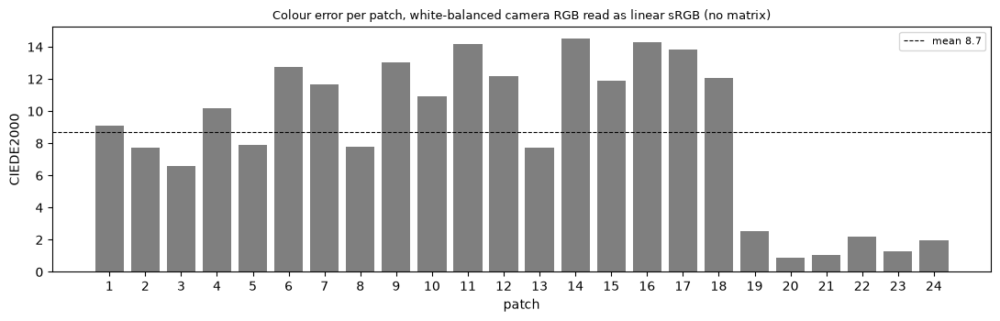

In [14]:
# =====================================================================================
# Baseline colour error BEFORE any matrix is fitted.
# White-balanced camera RGB is treated as if it were linear sRGB, converted to XYZ with the
# standard sRGB primaries (D65), adapted to the reference illuminant, and compared with the
# ColorChecker reference in CIELAB. Metric: CIEDE2000 (dE00). CIE76 dE*ab is shown too.
#
# Reference: colour-science, CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]
# (xyY -> XYZ). Install with:  uv add colour-science     (then restart the kernel)
#
# Needs from earlier cells: `wb` (output of white_balance_chart), PATCH_NAMES.
#   wb["balanced_means"] = (24, 3) white-balanced linear patch means.
# =====================================================================================

REF_NAME = "ColorChecker24 - After November 2014"

D65_WHITE = np.array([0.95047, 1.0, 1.08883])
SRGB_TO_XYZ_D65 = np.array([[0.4124564, 0.3575761, 0.1804375],      # standard sRGB primaries
                            [0.2126729, 0.7151522, 0.0721750],
                            [0.0193339, 0.1191920, 0.9503041]])
BRADFORD = np.array([[0.8951, 0.2664, -0.1614],
                     [-0.7502, 1.7135, 0.0367],
                     [0.0389, -0.0685, 1.0296]])
_EPS, _KAPPA = 216 / 24389, 24389 / 27


# ------------------------------- REUSABLE FUNCTIONS ---------------------------------
def xyY_to_XYZ(xyY):
    x, y, Y = xyY[:, 0], xyY[:, 1], xyY[:, 2]
    return np.stack([x * Y / y, Y, (1 - x - y) * Y / y], axis=1)


def load_reference(name=REF_NAME):
    """Reference XYZ (24, 3, Y of a perfect white = ~0.9) and the reference illuminant's
    white point XYZ (Y = 1), from colour-science. Patch order = the chart's patch order."""
    cc = colour.CCS_COLOURCHECKERS[name]
    xyY = np.array([np.asarray(v, dtype=float) for v in cc.data.values()])
    assert xyY.shape == (24, 3), f"expected 24 patches, got {xyY.shape}"
    if xyY[:, 2].max() > 2:                       # Y given on a 0-100 scale
        xyY[:, 2] /= 100
    ix, iy = np.asarray(cc.illuminant, dtype=float)[:2]
    white = np.array([ix / iy, 1.0, (1 - ix - iy) / iy])
    names = [str(k) for k in cc.data.keys()]
    return xyY_to_XYZ(xyY), white, names


def bradford_adapt(xyz, src_white, dst_white):
    """Chromatic adaptation of (N,3) XYZ from one white point to another (Bradford)."""
    gain = (BRADFORD @ dst_white) / (BRADFORD @ src_white)
    A = np.linalg.inv(BRADFORD) @ np.diag(gain) @ BRADFORD
    return xyz @ A.T


def xyz_to_lab(xyz, white):
    t = xyz / white
    f = np.where(t > _EPS, np.cbrt(t), (_KAPPA * t + 16) / 116)
    return np.stack([116 * f[:, 1] - 16, 500 * (f[:, 0] - f[:, 1]), 200 * (f[:, 1] - f[:, 2])], axis=1)


def ciede2000(lab1, lab2):
    """CIEDE2000 colour difference for (N,3) Lab arrays (Sharma, Wu, Dalal 2005)."""
    L1, a1, b1 = lab1.T
    L2, a2, b2 = lab2.T
    Cbar = (np.hypot(a1, b1) + np.hypot(a2, b2)) / 2
    G = 0.5 * (1 - np.sqrt(Cbar ** 7 / (Cbar ** 7 + 25 ** 7)))
    a1p, a2p = (1 + G) * a1, (1 + G) * a2
    C1p, C2p = np.hypot(a1p, b1), np.hypot(a2p, b2)
    h1p = np.degrees(np.arctan2(b1, a1p)) % 360
    h2p = np.degrees(np.arctan2(b2, a2p)) % 360
    dLp, dCp = L2 - L1, C2p - C1p
    zero = C1p * C2p == 0
    dh = h2p - h1p
    dh = np.where(dh > 180, dh - 360, np.where(dh < -180, dh + 360, dh))
    dh = np.where(zero, 0, dh)
    dHp = 2 * np.sqrt(C1p * C2p) * np.sin(np.radians(dh / 2))
    Lbp, Cbp = (L1 + L2) / 2, (C1p + C2p) / 2
    hs = h1p + h2p
    hbp = np.where(zero, hs, np.where(np.abs(h1p - h2p) <= 180, hs / 2,
                                      np.where(hs < 360, (hs + 360) / 2, (hs - 360) / 2)))
    T = (1 - 0.17 * np.cos(np.radians(hbp - 30)) + 0.24 * np.cos(np.radians(2 * hbp))
         + 0.32 * np.cos(np.radians(3 * hbp + 6)) - 0.20 * np.cos(np.radians(4 * hbp - 63)))
    dth = 30 * np.exp(-(((hbp - 275) / 25) ** 2))
    Rc = 2 * np.sqrt(Cbp ** 7 / (Cbp ** 7 + 25 ** 7))
    Sl = 1 + 0.015 * (Lbp - 50) ** 2 / np.sqrt(20 + (Lbp - 50) ** 2)
    Sc, Sh = 1 + 0.045 * Cbp, 1 + 0.015 * Cbp * T
    Rt = -np.sin(np.radians(2 * dth)) * Rc
    return np.sqrt((dLp / Sl) ** 2 + (dCp / Sc) ** 2 + (dHp / Sh) ** 2 + Rt * (dCp / Sc) * (dHp / Sh))


def baseline_delta_e(balanced_means, ref_xyz, white, names, norm_patch=19):
    """Colour error of white-balanced camera RGB read as linear sRGB (no matrix fitted).

    Steps: RGB -> XYZ (sRGB primaries, D65) -> Bradford to the reference illuminant -> ONE
    scalar so the Y of `norm_patch` (1-based, default 19 = white) equals its reference Y
    -> CIELAB (reference white) -> CIEDE2000 against the reference Lab.
    The scalar is exposure only, not a colour matrix.
    """
    rgb = np.asarray(balanced_means, dtype=np.float64)
    xyz = bradford_adapt(rgb @ SRGB_TO_XYZ_D65.T, D65_WHITE, white)
    i = norm_patch - 1
    scale = ref_xyz[i, 1] / xyz[i, 1]
    lab = xyz_to_lab(xyz * scale, white)
    ref_lab = xyz_to_lab(ref_xyz, white)
    de00 = ciede2000(ref_lab, lab)
    de76 = np.linalg.norm(lab - ref_lab, axis=1)
    table = pd.DataFrame({"name": names,
                          "L_ref": ref_lab[:, 0], "a_ref": ref_lab[:, 1], "b_ref": ref_lab[:, 2],
                          "L": lab[:, 0], "a": lab[:, 1], "b": lab[:, 2],
                          "dE00": de00, "dE76": de76}, index=range(1, 25))
    table.index.name = "patch"
    w = int(np.argmax(de00))
    return {"table": table, "mean": float(de00.mean()), "worst": float(de00.max()),
            "worst_patch": w + 1, "worst_name": names[w], "scale": float(scale),
            "mean76": float(de76.mean()), "worst76": float(de76.max())}


def report_baseline(res, clipped=None):
    t = res["table"]
    display(t.round(2))
    print(f"Metric: CIEDE2000 (dE00), CIELAB; reference = colour-science '{REF_NAME}'")
    print(f"Mean dE00  across 24 patches: {res['mean']:.2f}")
    print(f"Worst dE00:                   {res['worst']:.2f}  "
          f"(patch {res['worst_patch']}, {res['worst_name']})")
    print(f"(for reference, CIE76 dE*ab: mean {res['mean76']:.2f}, worst {res['worst76']:.2f})")
    print(f"Exposure scalar applied so patch 19 matches the reference Y: {res['scale']:.3f}")
    if clipped is not None and np.any(clipped):
        print(f"[warn] clipped patches included in these statistics: "
              f"{[int(i) + 1 for i in np.where(clipped)[0]]}")
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.bar(t.index, t["dE00"], color="tab:gray")
    ax.axhline(res["mean"], color="k", ls="--", lw=0.8, label=f"mean {res['mean']:.1f}")
    ax.set_xticks(t.index)
    ax.set_xlabel("patch")
    ax.set_ylabel("CIEDE2000")
    ax.set_title("Colour error per patch, white-balanced camera RGB read as linear sRGB (no matrix)",
                 fontsize=9)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()


# ----------------------------------- RUN --------------------------------------------
ref_xyz, ref_white, ref_names = load_reference()
print("reference patch order:", ref_names[0], "...", ref_names[18], "...", ref_names[23])
print("reference illuminant white XYZ:", ref_white.round(4))
res = baseline_delta_e(wb["balanced_means"], ref_xyz, ref_white, PATCH_NAMES)
report_baseline(res, wb["clipped"])

Metric: CIEDE2000 (dE00), CIELAB; reference = colour-science 'ColorChecker24 - After November 2014'

Mean dE00  across 24 patches: 8.68

Worst dE00:                   14.52  (patch 14, green)

7. Fit the three by three matrix that best maps your white balanced camera RGB to the reference XYZ in a least squares sense across all twenty four patches.
Deliverable: The matrix, and one sentence on whether its rows sum to something close to preserving a neutral.

In [16]:
# =====================================================================================
# Fit the 3x3 colour correction matrix M:   XYZ_est = M @ rgb      (rgb = white-balanced
# camera RGB, linear).  For all 24 patches at once:  XYZ_est = rgb_table @ M.T
#
# Needs from earlier cells:
#   wb                                  (white_balance_chart.py)   wb["balanced_means"] (24, 3)
#   ref_xyz, ref_white, PATCH_NAMES     (baseline_delta_e.py)
#   xyz_to_lab, ciede2000               (baseline_delta_e.py)
#   res                                 (optional: baseline result, for the before/after column)
# Needs scipy (installed with colour-science).
# ------------------------------- REUSABLE FUNCTIONS ---------------------------------
from scipy.optimize import minimize # <- needed for scipy for mimizing the mean 

def fit_ccm_lstsq(rgb, xyz):
    """Least-squares 3x3 matrix: minimises sum over patches of ||M @ rgb_i - xyz_i||^2.

    rgb, xyz: (N, 3). Closed form via the normal equations (solved with lstsq for stability).
    Returns M (3, 3) so that  xyz_est = rgb @ M.T
    """
    Mt, *_ = np.linalg.lstsq(np.asarray(rgb, float), np.asarray(xyz, float), rcond=None)
    return Mt.T


def fit_ccm_de00(rgb, xyz, white, m_start, maxiter=20000):
    """3x3 matrix that minimises the mean CIEDE2000 directly (numerical search, starts from
    the least-squares matrix). No closed form exists, so this is an iterative optimisation."""
    ref_lab = xyz_to_lab(xyz, white)

    def cost(m):
        return float(ciede2000(ref_lab, xyz_to_lab(rgb @ m.reshape(3, 3).T, white)).mean())

    r = minimize(cost, np.asarray(m_start, float).ravel(), method="Nelder-Mead",
                 options={"maxiter": maxiter, "maxfev": maxiter, "xatol": 1e-9, "fatol": 1e-9})
    r = minimize(cost, r.x, method="Nelder-Mead",                      # one restart
                 options={"maxiter": maxiter, "maxfev": maxiter, "xatol": 1e-9, "fatol": 1e-9})
    return r.x.reshape(3, 3)


def apply_ccm(rgb, M):
    """Camera RGB (..., 3) -> XYZ (..., 3)."""
    return np.asarray(rgb, float) @ np.asarray(M, float).T


def de00_of(M, rgb, ref_xyz, white):
    """Per-patch CIEDE2000 between the reference and the matrix-corrected camera values."""
    return ciede2000(xyz_to_lab(ref_xyz, white), xyz_to_lab(apply_ccm(rgb, M), white))


def leave_one_out(fit_fn, rgb, ref_xyz, white):
    """Fit on 23 patches, predict the held-out one; repeat for every patch.
    Returns per-patch CIEDE2000 of the HELD-OUT patches (honest, out-of-sample error)."""
    n = len(rgb)
    out = np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        M = fit_fn(rgb[keep], ref_xyz[keep])
        out[i] = de00_of(M, rgb[[i]], ref_xyz[[i]], white)[0]
    return out


def compare_methods(rgb, ref_xyz, white):
    """Least squares in XYZ vs direct CIEDE2000 minimisation: in-sample and leave-one-out."""
    m_ls = fit_ccm_lstsq(rgb, ref_xyz)
    fits = {
        "least squares in XYZ": (lambda r, x: fit_ccm_lstsq(r, x), m_ls),
        "minimise mean dE00":   (lambda r, x: fit_ccm_de00(r, x, white, fit_ccm_lstsq(r, x)),
                                 None),
    }
    rows, mats = [], {}
    for name, (fn, M) in fits.items():
        M = fn(rgb, ref_xyz) if M is None else M
        mats[name] = M
        d_in = de00_of(M, rgb, ref_xyz, white)
        d_cv = leave_one_out(fn, rgb, ref_xyz, white)
        rows.append({"method": name,
                     "fit mean dE00": d_in.mean(), "fit worst dE00": d_in.max(),
                     "leave-one-out mean": d_cv.mean(), "leave-one-out worst": d_cv.max()})
    return pd.DataFrame(rows).set_index("method"), mats


def report_ccm(rgb, ref_xyz, white, names, baseline_de=None):
    """Fit the matrix by least squares and print everything you need to judge it."""
    M = fit_ccm_lstsq(rgb, ref_xyz)
    est = apply_ccm(rgb, M)
    d = de00_of(M, rgb, ref_xyz, white)

    np.set_printoptions(precision=5, suppress=True)
    print("3x3 matrix M  (XYZ = M @ [R, G, B], white-balanced linear camera RGB -> XYZ):")
    print(M)
    print("\nColumns = XYZ of the camera's R, G and B 'primaries' in the balanced space:")
    for k, c in enumerate("RGB"):
        print(f"  {c}: X={M[0, k]:+.4f}  Y={M[1, k]:+.4f}  Z={M[2, k]:+.4f}")
    print(f"\nCondition number of M:            {np.linalg.cond(M):.1f}  (large = amplifies noise)")
    print(f"Condition number of the RGB data: {np.linalg.cond(rgb):.1f}")
    print(f"As Python:  M = np.array({np.round(M, 6).tolist()})")
    print(f"RMS error in XYZ over the 24 patches: {np.sqrt(np.mean((est - ref_xyz) ** 2)):.4f} "
          f"(reference Y of white = {ref_xyz[18, 1]:.3f})")

    tbl = pd.DataFrame({"name": names, "dE00 after matrix": d}, index=range(1, 25))
    tbl.index.name = "patch"
    if baseline_de is not None:
        tbl.insert(1, "dE00 before (sRGB read)", np.asarray(baseline_de))
    display(tbl.round(2))
    print(f"CIEDE2000 after the matrix:  mean {d.mean():.2f}   worst {d.max():.2f} "
          f"(patch {int(np.argmax(d)) + 1}, {names[int(np.argmax(d))]})")
    if baseline_de is not None:
        b = np.asarray(baseline_de)
        print(f"CIEDE2000 before:            mean {b.mean():.2f}   worst {b.max():.2f}")

    print("\nHow do we know it is the best? Compare methods (24 patches, 9 free numbers):")
    cmp_tbl, mats = compare_methods(rgb, ref_xyz, white)
    display(cmp_tbl.round(2))
    return M, tbl, cmp_tbl, mats


# ----------------------------------- RUN --------------------------------------------
rgb_wb = np.asarray(wb["balanced_means"], dtype=float)
baseline_de = res["table"]["dE00"].to_numpy() if "res" in globals() else None
M, ccm_table, ccm_compare, ccm_all = report_ccm(rgb_wb, ref_xyz, ref_white, PATCH_NAMES, baseline_de)
np.save("ccm_least_squares.npy", M)

3x3 matrix M  (XYZ = M @ [R, G, B], white-balanced linear camera RGB -> XYZ):
[[ 1.35031  0.72835  0.41223]
 [ 0.05326  2.52304  0.04544]
 [ 0.02328 -1.53228  3.65221]]

Columns = XYZ of the camera's R, G and B 'primaries' in the balanced space:
  R: X=+1.3503  Y=+0.0533  Z=+0.0233
  G: X=+0.7284  Y=+2.5230  Z=-1.5323
  B: X=+0.4122  Y=+0.0454  Z=+3.6522

Condition number of M:            3.4  (large = amplifies noise)
Condition number of the RGB data: 11.4
As Python:  M = np.array([[1.350308, 0.728352, 0.412233], [0.053264, 2.52304, 0.04544], [0.023278, -1.532276, 3.652208]])
RMS error in XYZ over the 24 patches: 0.0154 (reference Y of white = 0.881)


,name,dE00 before (sRGB read),dE00 after matrix
patch,,,
1,dark skin,9.12,3.43
2,light skin,7.71,4.24
3,blue sky,6.58,1.79
4,foliage,10.17,2.63
5,blue flower,7.89,1.00
6,bluish green,12.76,2.97
7,orange,11.68,4.13
8,purplish blue,7.81,4.60
9,moderate red,13.02,3.51


CIEDE2000 after the matrix:  mean 2.89   worst 8.91 (patch 15, red)
CIEDE2000 before:            mean 8.68   worst 14.52

How do we know it is the best? Compare methods (24 patches, 9 free numbers):


,fit mean dE00,fit worst dE00,leave-one-out mean,leave-one-out worst
method,,,,
least squares in XYZ,2.89,8.91,3.28,10.03
minimise mean dE00,2.49,10.28,2.79,10.67


I tried two different fitting methods to fit the color matrix that best maps our RGB to the reference XYZ, least squares (as the assignment mentions and mimimising mean dE00. Both methods improve on the no matrix basline from the previous question. The leave one out is included to get a sense of over fitting of the model, it does not appear that the model is over fitting (the leave one out mean would be much larger). Comparing the two methods the least squares does better on the fit worst dE00 while the mimimise mean dE00 does better on the mean dE00, so this represents a trade off of better mean or better worst fit patch. I will go with least squares going forward because that is the deliverable but this could be an engineering trade off to pick.

In [17]:
s = M.sum(axis=1)
print("row sums:", s.round(4))
print("normalised to Y = 1:", (s / s[1]).round(4), " vs reference white:", ref_white.round(4))
print("deviation (%):", (100 * (s / s[1] / ref_white - 1)).round(2))

row sums: [ 2.4909  2.6217  2.1432]
normalised to Y = 1: [ 0.9501  1.      0.8175]  vs reference white: [ 0.9642  1.      0.8249]
deviation (%): [-1.46  0.   -0.9 ]


I believe that this shows that the rows of the matrix sum to preserving neutrals relatively well.

8. Apply the matrix and report the error again. Identify which patches remain the worst, and explain in three or four sentences why the residual does not fall to zero no matter how good the fit is.
Deliverable: A figure of per patch ΔE before and after, the mean and worst value for each, the names of the two or three worst patches, and your written explanation.

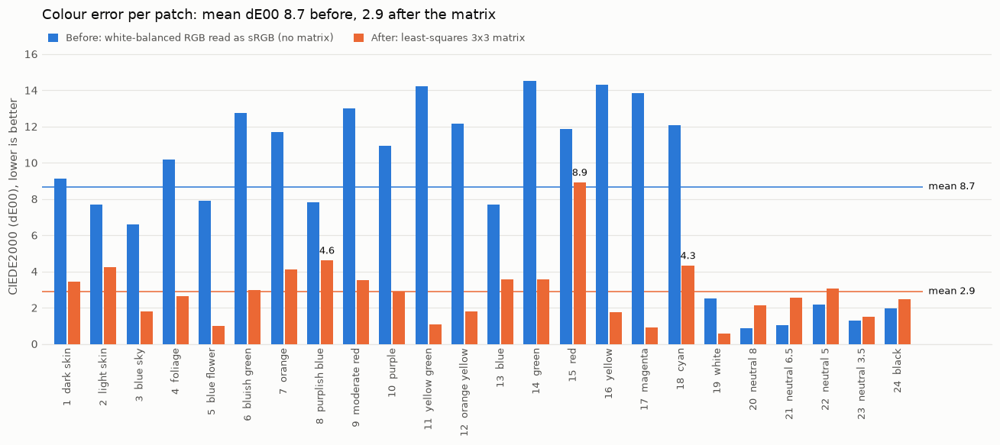

,mean dE00,worst dE00,worst patch
before (no matrix),8.68,14.52,14 green
after (least-squares matrix),2.89,8.91,15 red


Metric: CIEDE2000 (dE00), CIELAB under the reference illuminant
Mean dE00:  8.68 -> 2.89
Worst dE00: 14.52 -> 8.91

Worst patches after the matrix:
  patch 15  red            dE00  8.91   (before: 11.87)
  patch  8  purplish blue  dE00  4.60   (before:  7.81)
  patch 18  cyan           dE00  4.31   (before: 12.06)

Which way each is off (corrected minus reference, CIELAB):


,dL*,da*,db*,dC* (chroma)
15,-0.00,5.30,-15.28,-0.62
8,3.17,-7.38,4.34,-5.46
18,0.18,8.74,-0.94,-5.05


In [18]:
# =====================================================================================
# Apply the least-squares matrix and report the colour error again.
#
# Needs from earlier cells:
#   M                                   (fit_ccm.py)  the 3x3 least-squares matrix
#   wb                                  (white_balance_chart.py)  wb["balanced_means"] (24, 3)
#   ref_xyz, ref_white, PATCH_NAMES     (baseline_delta_e.py)
#   xyz_to_lab, ciede2000               (baseline_delta_e.py)
#   apply_ccm, de00_of                  (fit_ccm.py)
#   res                                 (baseline_delta_e.py result; recomputed if missing)


# chart colours: two validated categorical slots (blue, orange) on a light surface
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
C_BEFORE, C_AFTER = "#2a78d6", "#eb6834"


# ------------------------------- REUSABLE FUNCTIONS ---------------------------------
def worst_patches(de, names, k=3):
    """The k patches with the largest error: list of (patch number 1-24, name, dE)."""
    order = np.argsort(de)[::-1][:k]
    return [(int(i) + 1, names[i], float(de[i])) for i in order]


def error_direction(M, rgb, ref_xyz, white, idx):
    """How the corrected colour differs from the reference for the chosen patches
    (corrected minus reference, in CIELAB): lightness, a*, b*, and chroma."""
    ref_lab = xyz_to_lab(ref_xyz[idx], white)
    lab = xyz_to_lab(apply_ccm(rgb[idx], M), white)
    d = lab - ref_lab
    dC = np.hypot(lab[:, 1], lab[:, 2]) - np.hypot(ref_lab[:, 1], ref_lab[:, 2])
    return pd.DataFrame({"dL*": d[:, 0], "da*": d[:, 1], "db*": d[:, 2], "dC* (chroma)": dC},
                        index=[i + 1 for i in idx])


def plot_before_after(before, after, names, title=None, save=None):
    """Grouped bars: per-patch CIEDE2000 before and after the matrix."""
    before, after = np.asarray(before, float), np.asarray(after, float)
    n = len(before)
    x = np.arange(n)
    fig, ax = plt.subplots(figsize=(12, 5.4), dpi=110)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)

    w, off = 0.34, 0.19                       # two bars per patch with a ~2px surface gap
    ax.bar(x - off, before, w, color=C_BEFORE, linewidth=0, zorder=3,
           label="Before: white-balanced RGB read as sRGB (no matrix)")
    ax.bar(x + off, after, w, color=C_AFTER, linewidth=0, zorder=3,
           label="After: least-squares 3x3 matrix")

    # mean of each series, labelled at the right-hand end
    for v, c, txt in ((before.mean(), C_BEFORE, "mean"), (after.mean(), C_AFTER, "mean")):
        ax.hlines(v, -0.7, n - 0.3, color=c, lw=1.0, zorder=2)
        ax.text(n - 0.15, v, f"{txt} {v:.1f}", color=INK, fontsize=8.5, va="center", ha="left",
                zorder=4)                      # label sits in the right margin, off the bars

    # value labels only on the three worst bars after the matrix
    for i in np.argsort(after)[::-1][:3]:
        ax.text(i + off, after[i] + 0.25, f"{after[i]:.1f}", color=INK, fontsize=8.5,
                ha="center", va="bottom", zorder=4)

    ax.set_xticks(x)
    ax.set_xticklabels([f"{i + 1}  {nm}" for i, nm in enumerate(names)],
                       rotation=90, fontsize=8.5, color=INK_2)
    ax.set_xlim(-0.7, n + 1.6)                 # right margin for the mean labels
    ax.set_ylim(0, max(before.max(), after.max()) * 1.12)
    ax.set_ylabel("CIEDE2000 (dE00), lower is better", color=INK_2, fontsize=9.5)
    ax.tick_params(axis="y", colors=INK_2, labelsize=9, length=0)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.set_title(title or f"Colour error per patch: mean dE00 {before.mean():.1f} before, "
                          f"{after.mean():.1f} after the matrix",
                 loc="left", color=INK, fontsize=11.5, pad=26)
    leg = ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False,
                    fontsize=8.5, handlelength=1.0, handleheight=1.0, borderaxespad=0.2)
    for t in leg.get_texts():
        t.set_color(INK_2)
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=200, facecolor=SURFACE)
    return fig


def report_before_after(M, rgb, ref_xyz, white, names, before_de, save="delta_e_before_after.png"):
    before_de = np.asarray(before_de, float)
    after_de = de00_of(M, rgb, ref_xyz, white)

    plot_before_after(before_de, after_de, names, save=save)
    plt.show()

    summary = pd.DataFrame({"mean dE00": [before_de.mean(), after_de.mean()],
                            "worst dE00": [before_de.max(), after_de.max()],
                            "worst patch": [f"{int(np.argmax(before_de)) + 1} {names[int(np.argmax(before_de))]}",
                                            f"{int(np.argmax(after_de)) + 1} {names[int(np.argmax(after_de))]}"]},
                           index=["before (no matrix)", "after (least-squares matrix)"])
    display(summary.round(2))
    print("Metric: CIEDE2000 (dE00), CIELAB under the reference illuminant")
    print(f"Mean dE00:  {before_de.mean():.2f} -> {after_de.mean():.2f}")
    print(f"Worst dE00: {before_de.max():.2f} -> {after_de.max():.2f}")

    worst = worst_patches(after_de, names, 3)
    print("\nWorst patches after the matrix:")
    for num, nm, v in worst:
        print(f"  patch {num:>2}  {nm:<14} dE00 {v:5.2f}   (before: {before_de[num - 1]:5.2f})")
    idx = [w[0] - 1 for w in worst]
    print("\nWhich way each is off (corrected minus reference, CIELAB):")
    display(error_direction(M, rgb, ref_xyz, white, idx).round(2))
    #print(f"Saved: {save}")
    return after_de, summary, worst


# ----------------------------------- RUN --------------------------------------------
rgb_wb = np.asarray(wb["balanced_means"], dtype=float)
if "res" in globals():
    before_de = res["table"]["dE00"].to_numpy()
else:
    before_de = baseline_delta_e(rgb_wb, ref_xyz, ref_white, PATCH_NAMES)["table"]["dE00"].to_numpy()
after_de, ba_summary, worst3 = report_before_after(M, rgb_wb, ref_xyz, ref_white, PATCH_NAMES, before_de)

The residuals well never go to zeros no matter how good the fit is because the camera does not exactly match what is happening woth the cones in the eye. The camera measures from three color filters with different sensitivity curves than the eye. There could also be smaller effects from say sensor noise that means the fits residuals will never go to zero.

Note for the worst patches: can we run this on more charts and if the issue is from the camera ot the illumiation it should be the same pathces with issues in the same way, but if the issue is with the code these would be different?

### Part 3: How much of this belongs to the chart?

9. Repeat items 5 through 8 independently for all three charts photographed under one illuminant of your choosing, and report the three mean ΔE values and the three matrices. Keep track of which chart is which. The three are the same product and look identical, so if you lose the correspondence between the charts and your files there is nothing in the images to recover it from, and item 10 becomes a measurement of nothing in particular.
Deliverable: Three mean and three worst ΔE values, and a comment on whether the three matrices resemble one another. Compare their columns as directions rather than element by element: several elements of a color matrix sit near zero, and their relative differences explode without meaning anything.

=== Set2 / IMG_0355.DNG ===
patch finding: orientation check RMS 0.1/255 (small = good), grey row 19->24 gets darker: True
clipped patches left out of the fit: none
white balance gains (G = 1): R 1.400  G 1.000  B 3.227   (neutral-patch spread: R 3.0%, B 4.3%)
matrix M  (XYZ = M @ [R, G, B]):
  [[ 1.3503  0.7284  0.4122]
   [ 0.0533  2.523   0.0454]
   [ 0.0233 -1.5323  3.6522]]
neutral check: M's row sums scaled to Y=1 are off the reference white by [-1.46, 0.0, -0.9] %  (X, Y, Z)
mean dE00:  before 8.68  ->  after 2.89   (worst after: 8.91)
  worst 1: patch 15 red           dE00  8.91   (before 11.87)

=== Set2 / IMG_0356.DNG ===
patch finding: orientation check RMS 0.1/255 (small = good), grey row 19->24 gets darker: True
clipped patches left out of the fit: none
white balance gains (G = 1): R 1.404  G 1.000  B 3.216   (neutral-patch spread: R 2.6%, B 3.8%)
matrix M  (XYZ = M @ [R, G, B]):
  [[ 1.435   0.738   0.3904]
   [ 0.0921  2.5778  0.0286]
   [ 0.0421 -1.5429  3.7039]]
neutra

,mean dE00 before,mean dE00 after,worst dE00 after,three worst patches
chart,,,,
IMG_0355.DNG,8.68,2.89,8.91,15 red
IMG_0356.DNG,8.44,2.81,8.92,15 red
IMG_0357.DNG,8.53,2.74,8.99,15 red


Matrices scaled so that a neutral input gives Y = 1 (for comparing across charts):
IMG_0355.DNG:
[[ 0.515   0.2778  0.1572]
 [ 0.0203  0.9624  0.0173]
 [ 0.0089 -0.5844  1.393 ]]
IMG_0356.DNG:
[[ 0.5318  0.2735  0.1447]
 [ 0.0341  0.9553  0.0106]
 [ 0.0156 -0.5718  1.3726]]
IMG_0357.DNG:
[[ 0.5392  0.2613  0.1499]
 [ 0.0315  0.9614  0.0071]
 [ 0.0202 -0.605   1.3982]]
largest entry-by-entry difference between any two charts: 0.033


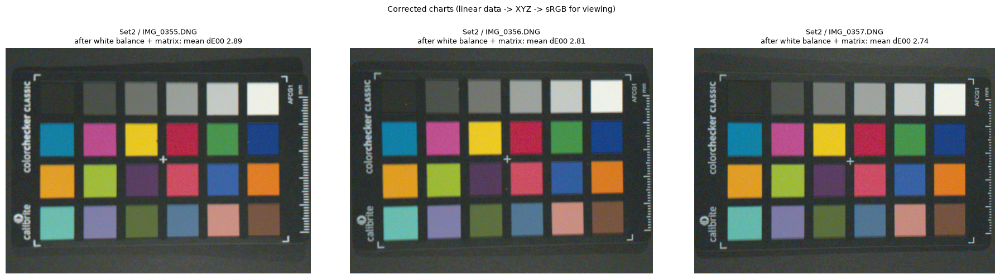

In [19]:
# =====================================================================================
# Clean walk-through for ONE lighting condition (one folder): for each of its three charts
#   find the 24 patches -> white balance -> fit the 3x3 matrix -> report the error -> view it.
# Every chart is processed on its own, because the targets differ.
#
# Needs from earlier cells (all already defined if you ran them in order):
#   patch_extraction_cell.py : find_colorchecker, PATCH_NAMES
#   white_balance_chart.py   : patch_clipped_fraction, neutral_gain_table, combine_gains,
#                              apply_gains, CLIP_FRAC_MAX
#   baseline_delta_e.py      : ref_xyz, ref_white, baseline_delta_e, bradford_adapt,
#                              D65_WHITE, SRGB_TO_XYZ_D65
#   fit_ccm.py               : fit_ccm_lstsq, de00_of
#   before_after.py          : worst_patches
#   lens-correction cells    : lens_corrected, raw_to_linear_quarter, list_dngs,
#                              find_condition_folders, CAPTURE_ROOT, SATURATION
# =====================================================================================
FOLDER_NAME = "Set2"      # the lighting condition to process
N_WORST = 1            # how many worst patches to name
MANUAL_CORNERS = {}       # only if detection fails for a file, e.g.
                          # {"IMG_0356.DNG": [(x, y), (x, y), (x, y), (x, y)]}  (TL, TR, BR, BL)

# ------------------------------- REUSABLE FUNCTIONS ---------------------------------
def process_chart(img, uncorrected, manual_corners=None):
    """Full chain for one chart image.

    img          lens-corrected linear RGB (H, W, 3)
    uncorrected  the same capture before lens correction (used only to test for clipping)
    Returns a dict with the patches, white-balance gains, matrix, errors and the balanced image.
    """
    # 1) locate the 24 patches and measure their mean linear RGB
    result = find_colorchecker(img, corners=manual_corners)

    # 2) clipped patches are left out of the white balance and of the matrix fit
    clipped = patch_clipped_fraction(uncorrected, result["polys"]) > CLIP_FRAC_MAX
    use = ~clipped
    if use.sum() < 12:
        raise RuntimeError(f"only {int(use.sum())} unclipped patches; too few to fit a matrix")

    # 3) white balance from the neutral patches (green = 1)
    tbl = neutral_gain_table(result, clipped)
    gains, spread = combine_gains(tbl)
    gains = gains / gains[1]
    rgb = result["means"] * gains                       # balanced patch means (24, 3)

    # 4) least-squares matrix: balanced camera RGB -> reference XYZ
    M = fit_ccm_lstsq(rgb[use], ref_xyz[use])

    # 5) error before (no matrix) and after (this matrix), over the patches used
    de_after = de00_of(M, rgb, ref_xyz, ref_white)
    de_before = baseline_delta_e(rgb, ref_xyz, ref_white, PATCH_NAMES)["table"]["dE00"].to_numpy()

    # does a neutral stay neutral? row sums of M, scaled to Y = 1, against the reference white
    s = M.sum(axis=1)
    neutral_dev = 100 * (s / s[1] / ref_white - 1)

    return {"result": result, "clipped": clipped, "use": use, "gains": gains, "spread": spread,
            "rgb": rgb, "M": M, "de_after": de_after, "de_before": de_before,
            "neutral_dev": neutral_dev, "img_wb": apply_gains(img, gains)}


def corrected_to_srgb(img_wb, M, white):
    """Matrix-corrected image -> sRGB for viewing. Balanced camera RGB -> XYZ (reference white)
    -> Bradford to D65 -> linear sRGB -> gamma. No extra brightness gain is applied: the
    matrix is fitted to the reference scale, so the white patch lands near 0.88 on its own."""
    xyz = img_wb.reshape(-1, 3).astype(np.float64) @ M.T
    xyz65 = bradford_adapt(xyz, white, D65_WHITE)
    lin = np.clip(xyz65 @ np.linalg.inv(SRGB_TO_XYZ_D65).T, 0, 1)
    enc = np.where(lin <= 0.0031308, 12.92 * lin, 1.055 * lin ** (1 / 2.4) - 0.055)
    return enc.reshape(img_wb.shape)


def print_chart_report(label, out, n_worst=N_WORST):
    r = out["result"]
    print(f"=== {label} ===")
    orient = ("manual corners" if np.isnan(r["orientation_rms"])
              else f"orientation check RMS {r['orientation_rms']:.1f}/255 (small = good)")
    print(f"patch finding: {orient}, grey row 19->24 gets darker: {r['grey_ramp_ok']}")
    ex = [int(i) + 1 for i in np.where(out["clipped"])[0]]
    print(f"clipped patches left out of the fit: {ex or 'none'}")
    g = out["gains"]
    print(f"white balance gains (G = 1): R {g[0]:.3f}  G {g[1]:.3f}  B {g[2]:.3f}   "
          f"(neutral-patch spread: R {out['spread']['R']:.1%}, B {out['spread']['B']:.1%})")
    print("matrix M  (XYZ = M @ [R, G, B]):")
    print("\n".join("  " + ln for ln in
                    np.array2string(out["M"], precision=4, suppress_small=True).splitlines()))
    print(f"neutral check: M's row sums scaled to Y=1 are off the reference white by "
          f"{np.round(out['neutral_dev'], 2).tolist()} %  (X, Y, Z)")
    u = out["use"]
    print(f"mean dE00:  before {out['de_before'][u].mean():.2f}  ->  after {out['de_after'][u].mean():.2f}"
          f"   (worst after: {out['de_after'][u].max():.2f})")
    de = np.where(u, out["de_after"], -1)
    for k, (num, nm, v) in enumerate(worst_patches(de, PATCH_NAMES, n_worst), 1):
        print(f"  worst {k}: patch {num:>2} {nm:<13} dE00 {v:5.2f}   (before {out['de_before'][num - 1]:5.2f})")
    print()


def show_corrected(outs, labels, margin=0.10, save=None):
    """The matrix-corrected charts side by side, cropped to the chart."""
    fig, axes = plt.subplots(1, len(outs), figsize=(6.2 * len(outs), 5.0), squeeze=False)
    for ax, out, lab in zip(axes[0], outs, labels):
        srgb = corrected_to_srgb(out["img_wb"], out["M"], ref_white)
        c = out["result"]["corners"]
        (x0, y0), (x1, y1) = c.min(axis=0), c.max(axis=0)
        m = margin * max(x1 - x0, y1 - y0)
        h, w = srgb.shape[:2]
        xa, xb = int(max(x0 - m, 0)), int(min(x1 + m, w))
        ya, yb = int(max(y0 - m, 0)), int(min(y1 + m, h))
        ax.imshow(srgb[ya:yb, xa:xb])
        u = out["use"]
        ax.set_title(f"{lab}\nafter white balance + matrix: mean dE00 {out['de_after'][u].mean():.2f}",
                     fontsize=9)
        ax.axis("off")
    fig.suptitle("Corrected charts (linear data -> XYZ -> sRGB for viewing)", fontsize=10, y=0.99)
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    if save:
        fig.savefig(save, dpi=150)
    return fig


# ----------------------------------- RUN --------------------------------------------
folder = next(f for f in find_condition_folders(CAPTURE_ROOT) if f.name == FOLDER_NAME)
*chart_files, _white_field = list_dngs(folder)          # first three = charts, last = white sheet

outs, labels = {}, []
for f in chart_files:
    key = (folder.name, f.name)
    uncorrected, _ = raw_to_linear_quarter(f, SATURATION, verbose=False)
    outs[f.name] = process_chart(lens_corrected[key], uncorrected, MANUAL_CORNERS.get(f.name))
    labels.append(f"{folder.name} / {f.name}")
    print_chart_report(labels[-1], outs[f.name])

# ---- side-by-side summary ----
rows = []
for f in chart_files:
    o = outs[f.name]
    u = o["use"]
    w = worst_patches(np.where(u, o["de_after"], -1), PATCH_NAMES, N_WORST)
    rows.append({"chart": f.name,
                 "mean dE00 before": o["de_before"][u].mean(),
                 "mean dE00 after": o["de_after"][u].mean(),
                 "worst dE00 after": o["de_after"][u].max(),
                 "three worst patches": ", ".join(f"{n} {nm}" for n, nm, _ in w)})
display(pd.DataFrame(rows).set_index("chart").round(2))

# ---- are the three matrices alike? (same lighting, so they should be) ----
# Scaled so a neutral maps to Y = 1; this removes each chart's exposure scale.
print("Matrices scaled so that a neutral input gives Y = 1 (for comparing across charts):")
norm = {n: o["M"] / o["M"].sum(axis=1)[1] for n, o in outs.items()}
for n, Mn in norm.items():
    print(f"{n}:\n{np.array2string(Mn, precision=4, suppress_small=True)}")
ms = list(norm.values())
if len(ms) > 1:
    spread = np.max([np.abs(a - b).max() for i, a in enumerate(ms) for b in ms[i + 1:]])
    print(f"largest entry-by-entry difference between any two charts: {spread:.3f}")

show_corrected(list(outs.values()), labels, save="corrected_charts.png")
plt.show()

The matrices do seem to resemble each other, esspecially when you look at the direction with in each matrix. also the worst patch is the same in each chart capture and the file images look quite similar. This seem to be a good check that the charts are similar and the pipeline is working?

10. Use the spread across those three charts as the uncertainty on your color accuracy, and record your results. If the three agree closely, say so: that is a result about the charts, not a failed measurement.
Deliverable: Your mean ΔE after correction as a value with an uncertainty, and the five color entries of your Project 1 results.json, which are the metric, the reference set, the mean ΔE before and after correction, and the worst patch after correction.

In [20]:
# =====================================================================================
# Colour accuracy of the reference set as  value +/- uncertainty, from the spread across
# the three charts. Run after folder_workflow.py (it uses `outs`, `chart_files`, PATCH_NAMES,
# FOLDER_NAME and worst_patches from the earlier cells).
#
# Uncertainty = sample standard deviation (n - 1) of the three per-chart mean dE00 values.
# =====================================================================================

REFERENCE_SET = FOLDER_NAME      # "Set2"
AGREE_REL = 0.10                 # spread below 10% of the mean counts as "agree closely"


# ------------------------------- REUSABLE FUNCTIONS ---------------------------------
def mean_with_spread(values):
    """Mean and sample standard deviation (n - 1) of a list of numbers."""
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.mean()), (float(v.std(ddof=1)) if len(v) > 1 else float("nan"))


def fmt_pm(mean, sd):
    """'value +/- uncertainty', uncertainty to 2 significant figures, value to the same decimals."""
    if not np.isfinite(sd) or sd < 1e-9 * max(1.0, abs(mean)):      # no spread (or rounding noise)
        return f"{mean:.2f}"
    exponent = int(f"{abs(sd):.1e}".split("e")[1])                  # exponent after rounding to 2 s.f.
    dec = max(1, 1 - exponent)
    return f"{mean:.{dec}f} ± {sd:.{dec}f}"


def accuracy_summary(outs, names):
    """Per-chart numbers and the across-chart mean +/- spread. `outs` is the dict made by
    process_chart (one entry per chart: de_before, de_after, use)."""
    charts = list(outs)
    use = [outs[c]["use"] for c in charts]
    before = np.array([outs[c]["de_before"][u].mean() for c, u in zip(charts, use)])
    after = np.array([outs[c]["de_after"][u].mean() for c, u in zip(charts, use)])
    improve = before - after                                    # paired, chart by chart

    # per-patch error after the matrix; patches left out of a chart's fit are NaN
    per_patch = np.array([np.where(u, outs[c]["de_after"], np.nan) for c, u in zip(charts, use)])
    avg_patch = np.nanmean(per_patch, axis=0)
    wp = int(np.nanargmax(avg_patch))                           # worst patch on average (0-based)
    wp_vals = per_patch[:, wp][np.isfinite(per_patch[:, wp])]

    each_worst = []
    for c, u in zip(charts, use):
        j = int(np.nanargmax(np.where(u, outs[c]["de_after"], np.nan)))
        each_worst.append((j + 1, float(outs[c]["de_after"][j])))

    return {"charts": charts, "before": before, "after": after, "improve": improve,
            "worst_patch": wp + 1, "worst_vals": wp_vals, "each_worst": each_worst,
            "per_patch": per_patch}


def report_accuracy(outs, names, reference_set=REFERENCE_SET, agree_rel=AGREE_REL,
                    save="color_accuracy.csv"):
    s = accuracy_summary(outs, names)
    mb, sb = mean_with_spread(s["before"])
    ma, sa = mean_with_spread(s["after"])
    mi, si = mean_with_spread(s["improve"])
    wp = s["worst_patch"]
    mw, sw = mean_with_spread(s["worst_vals"])

    # per-chart table: the raw material for the uncertainty
    rows = []
    for c, b, a, (wn, wv) in zip(s["charts"], s["before"], s["after"], s["each_worst"]):
        rows.append({"chart": c, "mean dE00 before": b, "mean dE00 after": a,
                     "worst patch after": f"{wn} {names[wn - 1]}", "worst dE00 after": wv})
    tbl = pd.DataFrame(rows).set_index("chart")
    display(tbl.round(2))

    rel = sa / ma if np.isfinite(sa) and ma > 0 else float("nan")
    print("Metric: CIEDE2000 (dE00). Uncertainty = sample standard deviation across the charts "
          f"(n = {len(s['charts'])}).\n")
    print(f"Reference set:                      {reference_set}  ({', '.join(s['charts'])})")
    print(f"Mean dE00 before correction:        {fmt_pm(mb, sb)}")
    print(f"Mean dE00 after correction:         {fmt_pm(ma, sa)}")
    print(f"Improvement (before - after):       {fmt_pm(mi, si)}")
    print(f"Range of the after values:          {s['after'].min():.2f} to {s['after'].max():.2f}")
    print(f"Worst patch after correction:       patch {wp}, {names[wp - 1]}, "
          f"dE00 {fmt_pm(mw, sw)}  (averaged over {len(s['worst_vals'])} charts)")
    own = [f"{c}: patch {n} {names[n - 1]} ({v:.2f})" for c, (n, v) in zip(s["charts"], s["each_worst"])]
    same = all(n == wp for n, _ in s["each_worst"])
    print(f"  worst patch in each chart:        " + ("the same patch in every chart" if same
          else "differs between charts") + "\n    " + "\n    ".join(own))

    if np.isfinite(rel):
        if rel <= agree_rel:
            pass
           # print(f"\nThe three charts agree closely: the spread is {rel:.1%} of the mean. That is a "
            #      f"result about the charts (the correction behaves the same on each target in "
             #     f"this lighting), not a failed measurement.")
        else:
            pass
           # print(f"\nThe three charts differ noticeably: the spread is {rel:.1%} of the mean, so the "
              #    f"uncertainty on the mean is substantial. Look at which chart departs "
               #   f"from the others (the table above).")
    if np.isfinite(si) and si > 1e-9 * max(1.0, abs(mi)):
        print(f"The improvement ({mi:.2f}) is about {mi / si:.0f} times its own spread ({si:.2f}).")
    elif np.isfinite(si):
        print(f"The improvement ({mi:.2f}) is identical on all charts.")

    out = pd.DataFrame([
        {"quantity": "mean dE00 before", "value": mb, "uncertainty (std)": sb},
        {"quantity": "mean dE00 after", "value": ma, "uncertainty (std)": sa},
        {"quantity": "improvement", "value": mi, "uncertainty (std)": si},
        {"quantity": f"worst patch after: {wp} {names[wp - 1]}", "value": mw, "uncertainty (std)": sw},
    ])
    out.insert(0, "reference set", reference_set)
    if save:
        out.to_csv(save, index=False)
       # print(f"\nSaved: {save}")
    return s, out


# ----------------------------------- RUN --------------------------------------------
acc, acc_table = report_accuracy(outs, PATCH_NAMES, save=f"color_accuracy_{REFERENCE_SET}.csv")

,mean dE00 before,mean dE00 after,worst patch after,worst dE00 after
chart,,,,
IMG_0355.DNG,8.68,2.89,15 red,8.91
IMG_0356.DNG,8.44,2.81,15 red,8.92
IMG_0357.DNG,8.53,2.74,15 red,8.99


Metric: CIEDE2000 (dE00). Uncertainty = sample standard deviation across the charts (n = 3).

Reference set:                      Set2  (IMG_0355.DNG, IMG_0356.DNG, IMG_0357.DNG)
Mean dE00 before correction:        8.55 ± 0.12
Mean dE00 after correction:         2.815 ± 0.076
Improvement (before - after):       5.733 ± 0.094
Range of the after values:          2.74 to 2.89
Worst patch after correction:       patch 15, red, dE00 8.937 ± 0.045  (averaged over 3 charts)
  worst patch in each chart:        the same patch in every chart
    IMG_0355.DNG: patch 15 red (8.91)
    IMG_0356.DNG: patch 15 red (8.92)
    IMG_0357.DNG: patch 15 red (8.99)
The improvement (5.73) is about 61 times its own spread (0.09).


### Part 4: How much of it belongs to the illuminant?

11. Take the matrix you fitted in item 7, apply it unchanged to the same chart photographed under the second illuminant, and report the error. Refit the white balance gains for the new illuminant, since that part is expected to change, but do not refit the matrix. Then scale the balanced values so that your reference neutral matches its published value before you compute ΔE. The rounds were not equally bright, and without that step you will mostly be measuring a difference in exposure rather than a difference in color.
Deliverable: Mean and worst ΔE under the second illuminant, beside the values you obtained under the first.

In part 7 I used the second illuinat set capture #1 to find the matrix, so for this comparision I will apply that matrix to the same chart in set 4 (again the first capture). 

Matrix from Set2 / IMG_0355.DNG applied unchanged to Set4 / IMG_0367.DNG
patch finding: grey row 19->24 gets darker: True   clipped patches left out: none
white balance gains (G = 1), refitted per illuminant:
  Set2: R 1.400  G 1.000  B 3.227
  Set4: R 2.490  G 1.000  B 1.489
exposure matched on patch 19 (white); 24 patches compared


,mean dE00,worst dE00,worst patch
capture,,,
"Set2 cap 1 (matrix fitted here), as obtained",2.89,8.91,15 red
"Set2 cap 1, exposure matched on the neutral",2.95,8.93,15 red
"Set4 cap 1, same matrix, refitted white balance, exposure matched",6.47,14.69,16 yellow


Metric: CIEDE2000 (dE00).
Under the second illuminant (Set2):  mean 2.89, worst 8.91 (15 red)
Under the fourth illuminant (Set4): mean 6.47, worst 14.69 (16 yellow)
Exposure scale applied to match the neutral: Set2 1.019, Set4 2.302  (ratio 2.26: how much brighter the Set4 balanced values had to be made to match)

Three worst patches under Set4:
  1: patch 16 yellow        dE00 14.69   (Set2:  1.87)
  2: patch  7 orange        dE00 12.31   (Set2:  4.25)
  3: patch  8 purplish blue dE00 11.85   (Set2:  4.86)


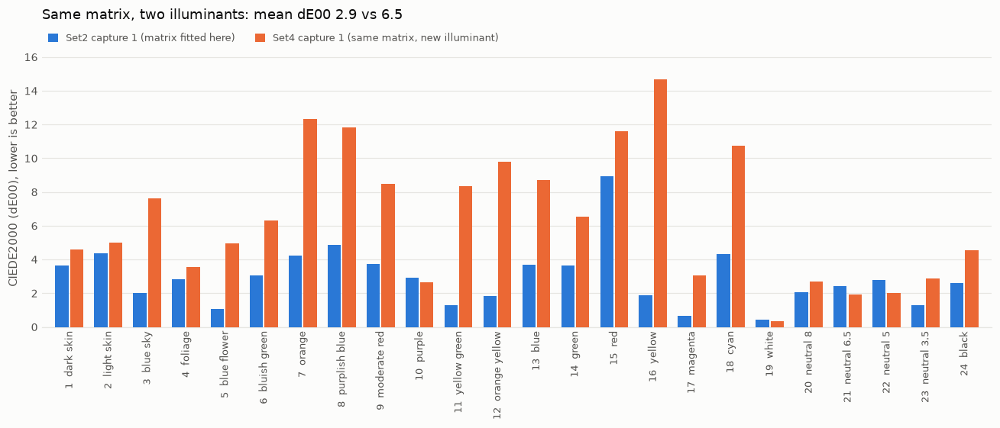

In [21]:
# =====================================================================================
# Apply the Set 2 / capture 1 matrix UNCHANGED to the same chart under another illuminant
# (Set 4, capture 1). The white-balance gains are refitted for the new light; the matrix is not.
# The balanced values are then scaled so the reference neutral matches its published value,
# so that the error measures colour, not a difference in exposure.
#
# Needs from earlier cells: outs, chart_files, MANUAL_CORNERS (folder_workflow.py),
#   find_colorchecker, patch_clipped_fraction, neutral_gain_table, combine_gains, CLIP_FRAC_MAX,
#   de00_of, worst_patches, ref_xyz, ref_white, PATCH_NAMES, lens_corrected,
#   raw_to_linear_quarter, list_dngs, find_condition_folders, CAPTURE_ROOT, SATURATION,
#   and the chart colours SURFACE, INK, INK_2, GRID, C_BEFORE, C_AFTER (before_after.py).
# =====================================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SRC_SET, SRC_CHART = "Set2", 0       # where the matrix was fitted
NEW_SET, NEW_CHART = "Set4", 0       # where it is applied (fourth illuminant, capture 1)
REFERENCE_NEUTRAL = 19               # 1-based patch whose published value sets the exposure
NEUTRAL_FALLBACK = (19, 20, 21, 22)  # used instead if the chosen neutral is clipped


# ------------------------------- REUSABLE FUNCTIONS ---------------------------------
def pick_neutral(clipped, preferred=REFERENCE_NEUTRAL):
    """The reference neutral: the preferred patch, or the next unclipped neutral."""
    for p in (preferred,) + tuple(x for x in NEUTRAL_FALLBACK if x != preferred):
        if not clipped[p - 1]:
            return p
    raise RuntimeError("every neutral patch is clipped; cannot match the exposure")


def exposure_scale(rgb, M, ref_xyz, patch):
    """Scalar s so that the reference neutral's luminance Y (after the matrix) equals its
    published Y. rgb is the (24, 3) balanced patch means; M is applied unchanged."""
    return float(ref_xyz[patch - 1, 1] / (M[1] @ rgb[patch - 1]))


def evaluate_fixed_matrix(rgb, M, use, patch):
    """dE00 of balanced patch means through the fixed matrix, after matching the exposure."""
    s = exposure_scale(rgb, M, ref_xyz, patch)
    de = de00_of(M * s, rgb, ref_xyz, ref_white)
    w = worst_patches(np.where(use, de, -1), PATCH_NAMES, 3)
    return {"scale": s, "de": de, "mean": float(de[use].mean()),
            "worst": float(de[use].max()), "worst_patches": w}


def plot_two_conditions(de_a, de_b, names, label_a, label_b, title):
    """Per-patch CIEDE2000 under two conditions, grouped bars."""
    n = len(de_a)
    x = np.arange(n)
    fig, ax = plt.subplots(figsize=(12, 5.2), dpi=110)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    ax.bar(x - 0.19, de_a, 0.34, color=C_BEFORE, linewidth=0, zorder=3, label=label_a)
    ax.bar(x + 0.19, de_b, 0.34, color=C_AFTER, linewidth=0, zorder=3, label=label_b)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{i + 1}  {nm}" for i, nm in enumerate(names)],
                       rotation=90, fontsize=8.5, color=INK_2)
    ax.set_xlim(-0.7, n - 0.3)
    ax.set_ylim(0, max(np.nanmax(de_a), np.nanmax(de_b)) * 1.12)
    ax.set_ylabel("CIEDE2000 (dE00), lower is better", color=INK_2, fontsize=9.5)
    ax.tick_params(axis="y", colors=INK_2, labelsize=9, length=0)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    for s_ in ("top", "right", "left"):
        ax.spines[s_].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.set_title(title, loc="left", color=INK, fontsize=11.5, pad=26)
    leg = ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False,
                    fontsize=8.5, handlelength=1.0, handleheight=1.0, borderaxespad=0.2)
    for t in leg.get_texts():
        t.set_color(INK_2)
    fig.tight_layout()
    return fig


# ----------------------------------- RUN --------------------------------------------
# --- the fixed matrix and the first illuminant's numbers (from the Set 2 workflow) ---
src_file = chart_files[SRC_CHART]
o_src = outs[src_file.name]
M = o_src["M"]                       # fitted on Set 2 capture 1; never refitted below
rgb_src, use_src = o_src["rgb"], o_src["use"]

# --- the new capture: find patches, check clipping, REFIT the white balance ---
folder_new = next(f for f in find_condition_folders(CAPTURE_ROOT) if f.name == NEW_SET)
file_new = list_dngs(folder_new)[NEW_CHART]
img_new = lens_corrected[(NEW_SET, file_new.name)]
uncorrected_new, _ = raw_to_linear_quarter(file_new, SATURATION, verbose=False)

res_new = find_colorchecker(img_new, MANUAL_CORNERS.get(file_new.name))
clipped_new = patch_clipped_fraction(uncorrected_new, res_new["polys"]) > CLIP_FRAC_MAX
use_new = ~clipped_new
gains_new, spread_new = combine_gains(neutral_gain_table(res_new, clipped_new))
gains_new = gains_new / gains_new[1]
rgb_new = res_new["means"] * gains_new

print(f"Matrix from {SRC_SET} / {src_file.name} applied unchanged to {NEW_SET} / {file_new.name}")
print(f"patch finding: grey row 19->24 gets darker: {res_new['grey_ramp_ok']}   "
      f"clipped patches left out: {[int(i) + 1 for i in np.where(clipped_new)[0]] or 'none'}")
g0 = o_src["gains"]
print(f"white balance gains (G = 1), refitted per illuminant:")
print(f"  {SRC_SET}: R {g0[0]:.3f}  G 1.000  B {g0[2]:.3f}")
print(f"  {NEW_SET}: R {gains_new[0]:.3f}  G 1.000  B {gains_new[2]:.3f}")

# --- one exposure-matching neutral, unclipped in BOTH captures; same patches compared ---
common = use_src & use_new
patch = pick_neutral(~common)
if patch != REFERENCE_NEUTRAL:
    print(f"[note] patch {REFERENCE_NEUTRAL} is clipped in one capture; exposure matched on patch "
          f"{patch} ({PATCH_NAMES[patch - 1]}) instead")
print(f"exposure matched on patch {patch} ({PATCH_NAMES[patch - 1]}); "
      f"{int(common.sum())} patches compared")

ev_src_raw = {"de": o_src["de_after"], "mean": float(o_src["de_after"][common].mean()),
              "worst": float(o_src["de_after"][common].max())}
ev_src = evaluate_fixed_matrix(rgb_src, M, common, patch)
ev_new = evaluate_fixed_matrix(rgb_new, M, common, patch)

# --- table: the deliverable ---
def wp_name(de):
    j = int(np.argmax(np.where(common, de, -1)))
    return f"{j + 1} {PATCH_NAMES[j]}"

table = pd.DataFrame([
    {"capture": f"{SRC_SET} cap {SRC_CHART + 1} (matrix fitted here), as obtained",
     "mean dE00": ev_src_raw["mean"], "worst dE00": ev_src_raw["worst"],
     "worst patch": wp_name(ev_src_raw["de"])},
    {"capture": f"{SRC_SET} cap {SRC_CHART + 1}, exposure matched on the neutral",
     "mean dE00": ev_src["mean"], "worst dE00": ev_src["worst"], "worst patch": wp_name(ev_src["de"])},
    {"capture": f"{NEW_SET} cap {NEW_CHART + 1}, same matrix, refitted white balance, exposure matched",
     "mean dE00": ev_new["mean"], "worst dE00": ev_new["worst"], "worst patch": wp_name(ev_new["de"])},
]).set_index("capture")
display(table.round(2))

print("Metric: CIEDE2000 (dE00).")
print(f"Under the second illuminant ({SRC_SET}):  mean {ev_src_raw['mean']:.2f}, worst {ev_src_raw['worst']:.2f} "
      f"({wp_name(ev_src_raw['de'])})")
print(f"Under the fourth illuminant ({NEW_SET}): mean {ev_new['mean']:.2f}, worst {ev_new['worst']:.2f} "
      f"({wp_name(ev_new['de'])})")
print(f"Exposure scale applied to match the neutral: {SRC_SET} {ev_src['scale']:.3f}, "
      f"{NEW_SET} {ev_new['scale']:.3f}  (ratio {ev_new['scale'] / ev_src['scale']:.2f}: "
      f"how much brighter the {NEW_SET} balanced values had to be made to match)")
print(f"\nThree worst patches under {NEW_SET}:")
for k, (num, nm, v) in enumerate(ev_new["worst_patches"], 1):
    print(f"  {k}: patch {num:>2} {nm:<13} dE00 {v:5.2f}   ({SRC_SET}: {ev_src['de'][num - 1]:5.2f})")

plot_two_conditions(ev_src["de"], ev_new["de"], PATCH_NAMES,
                    f"{SRC_SET} capture {SRC_CHART + 1} (matrix fitted here)",
                    f"{NEW_SET} capture {NEW_CHART + 1} (same matrix, new illuminant)",
                    f"Same matrix, two illuminants: mean dE00 {ev_src['mean']:.1f} vs {ev_new['mean']:.1f}")
#plt.savefig("fixed_matrix_two_illuminants.png", dpi=150, facecolor=SURFACE)
plt.show()

Result;

Under the second illuminant (Set2):  mean 2.89, worst 8.91 (15 red)

Under the fourth illuminant (Set4): mean 6.47, worst 14.69 (16 yellow)

12. Do the same for the third illuminant.
Deliverable: Mean and worst ΔE under the third illuminant, and a single figure comparing per patch ΔE across all three.

Matrix from Set2 / IMG_0355.DNG applied unchanged to Set3 / IMG_0359.DNG
patch finding: grey row 19->24 gets darker: True   clipped patches left out: none
white balance gains (G = 1), refitted per illuminant:
  Set2: R 1.400  G 1.000  B 3.227
  Set3: R 1.324  G 1.000  B 3.234
exposure matched on patch 19 (white); 24 patches compared


,mean dE00,worst dE00,worst patch
capture,,,
"Set2 cap 1 (matrix fitted here), as obtained",2.89,8.91,15 red
"Set2 cap 1, exposure matched on the neutral",2.95,8.93,15 red
"Set3 cap 1, same matrix, refitted white balance, exposure matched",3.88,14.69,15 red


Metric: CIEDE2000 (dE00).
Under the second illuminant (Set2):  mean 2.89, worst 8.91 (15 red)
Under the third illuminant (Set3): mean 3.88, worst 12.90 (15 red)
Exposure scale applied to match the neutral: Set2 1.019, Set3 1.555  (ratio 2.26: how much brighter the Set3 balanced values had to be made to match)

Three worst patches under Set3:
  1: patch 15 red           dE00 12.90   (Set2:  8.93)
  2: patch  2 light skin    dE00  8.57   (Set2:  4.37)
  3: patch  9 moderate red  dE00  6.24   (Set2:  3.75)


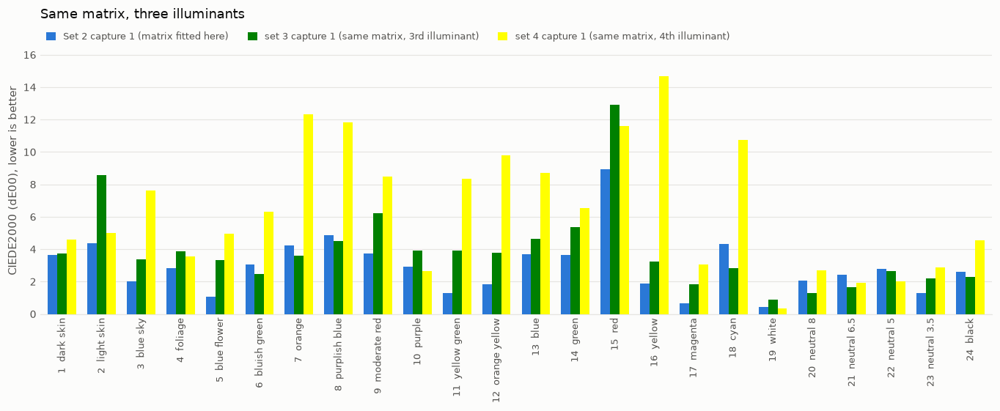

In [33]:
def plot_three_conditions(de_a, de_b, de_c, names, label_a, label_b, label_c, title):
    """Per-patch CIEDE2000 under three conditions, grouped bars."""
    n = len(de_a)
    x = np.arange(n)

    fig, ax = plt.subplots(figsize=(12.5, 5.2), dpi=110)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)

    # Bar spacing: three bars centered around each x-position
    width = 0.24
    offsets = [-width, 0, width]

    ax.bar(x + offsets[0], de_a, width,
           color=C_BEFORE, linewidth=0, zorder=3, label=label_a)

    ax.bar(x + offsets[1], de_b, width,
           color="green", linewidth=0, zorder=3, label=label_b)

    ax.bar(x + offsets[2], de_c, width,
           color="yellow", linewidth=0, zorder=3, label=label_c)

    # X-axis labels
    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{i + 1}  {nm}" for i, nm in enumerate(names)],
        rotation=90, fontsize=8.5, color=INK_2
    )

    # Leave room for the outer bars
    ax.set_xlim(-0.55, n - 0.45)

    # Include all three conditions when setting the y-axis limit
    ymax = max(np.nanmax(de_a), np.nanmax(de_b), np.nanmax(de_c))
    ax.set_ylim(0, ymax * 1.12)

    # Axis formatting
    ax.set_ylabel(
        "CIEDE2000 (dE00), lower is better",
        color=INK_2, fontsize=9.5
    )
    ax.tick_params(axis="y", colors=INK_2, labelsize=9, length=0)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)

    for s_ in ("top", "right", "left"):
        ax.spines[s_].set_visible(False)

    ax.spines["bottom"].set_color(GRID)

    ax.set_title(title, loc="left", color=INK, fontsize=11.5, pad=26)

    # Legend
    leg = ax.legend(
        loc="lower left", bbox_to_anchor=(0, 1.0),
        ncol=3, frameon=False, fontsize=8.5,
        handlelength=1.0, handleheight=1.0, borderaxespad=0.2
    )

    for t in leg.get_texts():
        t.set_color(INK_2)

    fig.tight_layout()
    return fig

SRC_SET, SRC_CHART = "Set2", 0       # where the matrix was fitted
NEW_SET, NEW_CHART = "Set3", 0       # where it is applied (fourth illuminant, capture 1)
REFERENCE_NEUTRAL = 19               # 1-based patch whose published value sets the exposure
NEUTRAL_FALLBACK = (19, 20, 21, 22)  # used instead if the chosen neutral is clipped

# ----------------------------------- RUN --------------------------------------------
# --- the fixed matrix and the first illuminant's numbers (from the Set 2 workflow) ---
src_file = chart_files[SRC_CHART]
o_src = outs[src_file.name]
M = o_src["M"]                       # fitted on Set 2 capture 1; never refitted below
rgb_src, use_src = o_src["rgb"], o_src["use"]

# --- the new capture: find patches, check clipping, REFIT the white balance ---
folder_new = next(f for f in find_condition_folders(CAPTURE_ROOT) if f.name == NEW_SET)
file_new = list_dngs(folder_new)[NEW_CHART]
img_new = lens_corrected[(NEW_SET, file_new.name)]
uncorrected_new, _ = raw_to_linear_quarter(file_new, SATURATION, verbose=False)

res_new = find_colorchecker(img_new, MANUAL_CORNERS.get(file_new.name))
clipped_new = patch_clipped_fraction(uncorrected_new, res_new["polys"]) > CLIP_FRAC_MAX
use_new = ~clipped_new
gains_new, spread_new = combine_gains(neutral_gain_table(res_new, clipped_new))
gains_new = gains_new / gains_new[1]
rgb_new = res_new["means"] * gains_new

print(f"Matrix from {SRC_SET} / {src_file.name} applied unchanged to {NEW_SET} / {file_new.name}")
print(f"patch finding: grey row 19->24 gets darker: {res_new['grey_ramp_ok']}   "
      f"clipped patches left out: {[int(i) + 1 for i in np.where(clipped_new)[0]] or 'none'}")
g0 = o_src["gains"]
print(f"white balance gains (G = 1), refitted per illuminant:")
print(f"  {SRC_SET}: R {g0[0]:.3f}  G 1.000  B {g0[2]:.3f}")
print(f"  {NEW_SET}: R {gains_new[0]:.3f}  G 1.000  B {gains_new[2]:.3f}")

# --- one exposure-matching neutral, unclipped in BOTH captures; same patches compared ---
common = use_src & use_new
patch = pick_neutral(~common)
if patch != REFERENCE_NEUTRAL:
    print(f"[note] patch {REFERENCE_NEUTRAL} is clipped in one capture; exposure matched on patch "
          f"{patch} ({PATCH_NAMES[patch - 1]}) instead")
print(f"exposure matched on patch {patch} ({PATCH_NAMES[patch - 1]}); "
      f"{int(common.sum())} patches compared")

ev_src_raw = {"de": o_src["de_after"], "mean": float(o_src["de_after"][common].mean()),
              "worst": float(o_src["de_after"][common].max())}
ev_src = evaluate_fixed_matrix(rgb_src, M, common, patch)
ev_new_3 = evaluate_fixed_matrix(rgb_new, M, common, patch)

# --- table: the deliverable ---
def wp_name(de):
    j = int(np.argmax(np.where(common, de, -1)))
    return f"{j + 1} {PATCH_NAMES[j]}"

table = pd.DataFrame([
    {"capture": f"{SRC_SET} cap {SRC_CHART + 1} (matrix fitted here), as obtained",
     "mean dE00": ev_src_raw["mean"], "worst dE00": ev_src_raw["worst"],
     "worst patch": wp_name(ev_src_raw["de"])},
    {"capture": f"{SRC_SET} cap {SRC_CHART + 1}, exposure matched on the neutral",
     "mean dE00": ev_src["mean"], "worst dE00": ev_src["worst"], "worst patch": wp_name(ev_src["de"])},
    {"capture": f"{NEW_SET} cap {NEW_CHART + 1}, same matrix, refitted white balance, exposure matched",
     "mean dE00": ev_new_3["mean"], "worst dE00": ev_new["worst"], "worst patch": wp_name(ev_new_3["de"])},
]).set_index("capture")
display(table.round(2))

print("Metric: CIEDE2000 (dE00).")
print(f"Under the second illuminant ({SRC_SET}):  mean {ev_src_raw['mean']:.2f}, worst {ev_src_raw['worst']:.2f} "
      f"({wp_name(ev_src_raw['de'])})")
print(f"Under the third illuminant ({NEW_SET}): mean {ev_new_3['mean']:.2f}, worst {ev_new_3['worst']:.2f} "
      f"({wp_name(ev_new_3['de'])})")
print(f"Exposure scale applied to match the neutral: {SRC_SET} {ev_src['scale']:.3f}, "
      f"{NEW_SET} {ev_new_3['scale']:.3f}  (ratio {ev_new['scale'] / ev_src['scale']:.2f}: "
      f"how much brighter the {NEW_SET} balanced values had to be made to match)")
print(f"\nThree worst patches under {NEW_SET}:")
for k, (num, nm, v) in enumerate(ev_new_3["worst_patches"], 1):
    print(f"  {k}: patch {num:>2} {nm:<13} dE00 {v:5.2f}   ({SRC_SET}: {ev_src['de'][num - 1]:5.2f})")

plot_three_conditions(ev_src["de"], ev_new_3["de"], ev_new["de"], PATCH_NAMES,
                    f"Set 2 capture 1 (matrix fitted here)",
                    f"set 3 capture 1 (same matrix, 3rd illuminant)",
                    f"set 4 capture 1 (same matrix, 4th illuminant)",
                    f"Same matrix, three illuminants")
#plt.savefig("fixed_matrix_two_illuminants.png", dpi=150, facecolor=SURFACE)
plt.show()

13. Interpret the comparison. State which transfer degraded more, say whether the degradation tracks the change in color temperature or the change in spectral shape, and explain what that implies about whether a single matrix stored in a camera can be correct under every light.
Deliverable: A written analysis, four to six sentences, referring to your own numbers.

The 4th set of captures performed the worst, mean 6.47 and worst 14.69 (16 yellow), both the mean and the worst were higher than when applying the correction matrix to the 2nd or 3rd illuminant conditions. Looking at indevidual patches it seems liek the trend is worse for the middle pathces #7-18 (would these be described as brighter colors). The 4th set is captured outside which may have the least controlled lighting (may be uneven or just more different) so it makes sense that it is farther off. The 3rd illuinate is still off from the 2nd when applying the matrix fitted to the second (was the the third the incondescent light source?). THis one seems to have largest mean (and most different when compared to set 2) in the redish pathces. I'm nto sure, but maybe the spectrum of light from this (3rd) light source has mroe longer wave length (redish) light and that would push the red up relative to the 2nd light source? Either way I believe that this shows that you can not use just one matrix fitted under one illuminate and expect it to work under all illuminates, maybe because different spectras of light reflecting off the chart then look different for the same patch when mesured with a camera sensor.

### Reflections

14. What did you learn?

    I think I did not get much from the color science lecture so this assignment was a good oportunity to go over the material again. For example the CEI XYZ color space and why we need this took me a bit to understand, also the steps of white balance and removing the shadow around the edges I had not thought about or why we would need them (neurals come out as neutrals and must be done before interpolation so the interpolation sees balanced data).

15. I used Ai heavily for the coding and figure generation. I feel like I wonder what the correct balance here is, for example it is using open CV packages and other python I do not know. Is it important for me to know all this, how much time should I spend reading open CV documentation/practicing python? Is what is important to know the course concepts and the coding skill mater less? If the coding skill matter then I definitly need to practice my python more. I guess this is a bigger question regarding AI tools and work.

AI reflection: I kinda talked about this in question 15. I guess as you mention in the assignment what is always important is verifying outputs and producing uncertainties (and this stays relevant whether the code is writen with AI tool or all by hand). Repeating measurements of three charts as well as the testing under different condtions (illuminations) and understanding what this means for your measuements is always good science/engineering.